# Synthetic clot-time benchmark

## Goal

Generating ten synthetic, instrument-style clotting datasets with known gel times, then comparing time-domain, Fourier, STFT, CWT, DWT, fast-CWT, and change-point methods against those labels. Each scenario has three noise realizations and at least 10,000 rows per realization. Observations and ground-truth labels are saved separately.

This is a controlled algorithm benchmark, not clinical data or a validated Haemograph digital twin. The methods all receive the same measurements, preprocessing, windows, and event labels. The analysis does not presume that wavelets will outperform Fourier methods.

## Gel-point definition and research traceability

Time zero is activator addition. The primary truth is the synthetic time \(T_{GP}\) where the Winter–Chambon condition is met:

\[
G'(\omega)\propto\omega^\alpha,\qquad
G''(\omega)\propto\omega^\alpha,\qquad
\delta(\omega)=\tan^{-1}(G''/G')\text{ is frequency-independent at }T_{GP}.
\]

The frequency-independent gel criterion comes from Winter and Chambon, “Analysis of Linear Viscoelasticity of a Crosslinking Polymer at the Gel Point,” *Journal of Rheology* 30 (1986), DOI 10.1122/1.549853. The project PDF is citation-only; the criterion is restated with equations by Hawkins et al. (2010), paper p. 893, section “Rheometrical considerations” (PDF p. 3). Their fibrin–thrombin results report a frequency-independent phase angle at the gel point and a rapid post-point increase in \(G'\) (paper p. 896; PDF p. 6). Their tested temperature and thrombin conditions were subphysiological, so the reported values guide qualitative design only.

The gelation progress follows the logistic ODE \(dc/dt=k c(1-c)\), initialized so \(c(T_{GP})=0.5\). To make the cross-frequency gel signature measurable against the chosen 40-second window, the synthetic storage and loss exponents and phase spread diverge more clearly away from this midpoint. This is an intentionally controlled challenge design; it is not a claim that every real clot follows this exact trajectory. This is a transparent synthetic design assumption, not a clot-kinetics equation claimed from the literature. The synthetic moduli are constructed to satisfy the Winter–Chambon condition at the ODE midpoint.

The \(G'=G''\) crossover is stored separately as a secondary comparator. It is not treated as interchangeable with \(T_{GP}\).

**Paper and page references used in this notebook**

- Hawkins, Lawrence, Williams et al. (2010), “The development of rheometry for strain-sensitive gelling systems and its application in a study of fibrin–thrombin gel formation,” *Rheologica Acta* 49, 891–900: gel-point criterion and sample-mutation discussion, pp. 893–894 (PDF pp. 3–4); fibrin phase-angle range and post-point modulus rise, p. 896 (PDF p. 6).
- Hawkins et al. (2008), “A study of gelatin gelation by Fourier transform mechanical spectroscopy,” *Journal of Non-Newtonian Fluid Mechanics* 148, 127–133: FTMS and gel-point treatment, pp. 128–130 (PDF pp. 2–4).
- Armstrong et al. (2021), “A simple approach for adding thixotropy to an elasto-visco-plastic rheological model to facilitate structural interrogation of human blood,” *Journal of Non-Newtonian Fluid Mechanics* 290, 104503: blood structure ODEs, Eqs. 11–16, pp. 5–6. These describe shear-dependent blood microstructure, not fibrin clot kinetics; they are not used as the clot-time law here.
- Arts and van den Broek (2022), “The fast continuous wavelet transformation (fCWT) for real-time, high-quality, noise-resistant time–frequency analysis,” *Nature Computational Science* 2, 47–58: fCWT algorithm and benchmarks, pp. 47–58, DOI 10.1038/s43588-021-00183-z.
- Torrence and Compo (1998), “A Practical Guide to Wavelet Analysis,” *Bulletin of the American Meteorological Society* 79(1), 61–78: Morlet function Eq. (1), CWT convolution Eqs. (2)–(4), and Morlet/Paul/DOG definitions in Table 1, pp. 62–64.
- Mallat (1989), “A Theory for Multiresolution Signal Decomposition: The Wavelet Representation,” *IEEE Transactions on Pattern Analysis and Machine Intelligence* 11(7), 674–693: multiresolution basis for the DWT comparisons (DOI 10.1109/34.192463).
- Demšar (2006), “Statistical Comparisons of Classifiers over Multiple Data Sets,” *JMLR* 7, 1–30: Wilcoxon signed-rank test, §3.1.3, pp. 6–7; Friedman and Nemenyi critical-difference methods, §3.2.2, pp. 10–11; diagram interpretation, §3.2.4, p. 14.
- Saito and Rehmsmeier (2015), “The Precision-Recall Plot Is More Informative than the ROC Plot When Evaluating Binary Classifiers on Imbalanced Datasets,” *PLOS ONE* 10(3), e0118432: Introduction and Results and Discussion, especially the simulation comparison; motivates reporting precision–recall alongside ROC (DOI 10.1371/journal.pone.0118432).

No universal accuracy cutoff is imposed. Timing success is shown at ±5, ±10, and ±30 seconds as sensitivity points, not validated acceptance thresholds.

In [ ]:
# Importing the scientific stack and locating the notebook folder
from pathlib import Path
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pywt
from scipy import signal, stats
from scipy.integrate import solve_ivp
from scipy.ndimage import gaussian_filter1d
from scipy.special import expit
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve

warnings.filterwarnings("ignore", category=RuntimeWarning)

search_directories = [Path.cwd(), *Path.cwd().parents]
notebook_directory = None
for search_directory in search_directories:
    if search_directory.name == "Syn_code_new":
        notebook_directory = search_directory
        break
    if (search_directory / "Syn_code_new").exists():
        notebook_directory = search_directory / "Syn_code_new"
        break
if notebook_directory is None:
    notebook_directory = Path("/Users/riamishra/Desktop/Haemograph_Project/Syn_code_new")

data_directory = notebook_directory / "data"
output_directory = notebook_directory / "outputs"
figure_directory = output_directory / "figures"
for folder in [data_directory, output_directory, figure_directory]:
    folder.mkdir(parents=True, exist_ok=True)

random_seed = 443
replicate_count = 3
window_seconds = 40.0
hop_seconds = 10.0
event_window_seconds = 30.0
timing_tolerances_seconds = [5.0, 10.0, 30.0]

plot_colours = {
    "Baseline": "#6C757D", "Fourier": "#E76F51", "STFT": "#F4A261",
    "CWT": "#2A9D8F", "DWT": "#457B9D", "Truth": "#263238",
}
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.22,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
})

try:
    import ruptures
    pelt_status = "available"
except Exception as error:
    ruptures = None
    pelt_status = f"unavailable: {type(error).__name__}: {error}"

try:
    import fcwt
    fcwt_status = "available"
except Exception as error:
    fcwt = None
    fcwt_status = f"unavailable: {type(error).__name__}: {error}"

print(f"Notebook directory: {notebook_directory}")
print(f"Optional PELT package: {pelt_status}")
print(f"Optional fCWT package: {fcwt_status}")

## Ten scenarios

The ten scenarios cover clean, fast, and slow clotting; weak signal with limited pre-gel support; baseline drift; nonlinear harmonic distortion; irregular sampling with a data gap across the clot point; clipping; a late clot with limited post-gel support and an instrument impulse; and a two-stage clot with an intentionally implausible 1000-fold stress-scale fault. Every scenario has three independent noise realizations and a separately stored known clot time.

Each scenario CSV contains three independent replicates. The manifest checks scenario-level and replicate-level row counts, while quality summaries record SNR, missingness, gap size, clipping, and amplitude-fidelity error.


In [ ]:
# Defining ten parameter-diverse clotting scenarios
scenario_configurations = [
    {"dataset_id":"SYN01","name":"clean_gradual_clot","duration_s":600,"fs_hz":50,"gel_s":300,"width_s":55,"strain":0.010,"noise":0.015,"drift":0.00,"jitter":0.00,"dropout":0.000,"harmonic":0.010,"clip":None,"gain":1.0,"stage2":0.0,"status":"good","frequencies":[0.2,0.5,1.0,2.0],"description":"Low-noise gradual reference clot."},
    {"dataset_id":"SYN02","name":"fast_clot_high_rate","duration_s":600,"fs_hz":100,"gel_s":210,"width_s":28,"strain":0.010,"noise":0.045,"drift":0.00,"jitter":0.00,"dropout":0.000,"harmonic":0.015,"clip":None,"gain":1.0,"stage2":0.0,"status":"good","frequencies":[0.2,0.5,1.0,2.0,3.2],"description":"Fast transition with high sampling and moderate noise."},
    {"dataset_id":"SYN03","name":"slow_clot_low_rate","duration_s":900,"fs_hz":20,"gel_s":620,"width_s":145,"strain":0.010,"noise":0.025,"drift":0.00,"jitter":0.00,"dropout":0.000,"harmonic":0.008,"clip":None,"gain":1.0,"stage2":0.0,"status":"good","frequencies":[0.2,0.5,1.0,2.0],"description":"Slow transition at the lowest sample rate."},
    {"dataset_id":"SYN04","name":"weak_signal_early_gel_limited_pregel","duration_s":600,"fs_hz":50,"gel_s":42,"gel_min_fraction":0.03,"gel_max_fraction":0.95,"width_s":24,"strain":0.006,"noise":0.080,"drift":0.00,"jitter":0.00,"dropout":0.000,"harmonic":0.010,"clip":None,"gain":1.0,"stage2":0.0,"status":"challenging","frequencies":[0.2,0.5,1.0,2.0],"description":"Weak response near the noise floor with very limited pre-gel observations."},
    {"dataset_id":"SYN05","name":"drifting_baseline","duration_s":900,"fs_hz":25,"gel_s":450,"width_s":70,"strain":0.012,"noise":0.025,"drift":0.10,"jitter":0.00,"dropout":0.000,"harmonic":0.010,"clip":None,"gain":1.0,"stage2":0.0,"status":"degraded","frequencies":[0.2,0.5,1.0,2.0],"description":"Slow stress baseline and temperature drift."},
    {"dataset_id":"SYN06","name":"large_strain_harmonics","duration_s":600,"fs_hz":50,"gel_s":330,"width_s":50,"strain":0.075,"noise":0.025,"drift":0.00,"jitter":0.00,"dropout":0.000,"harmonic":0.180,"clip":None,"gain":1.0,"stage2":0.0,"status":"degraded","frequencies":[0.2,0.5,1.0,2.0,3.2],"description":"Large strain with deliberate third-harmonic distortion."},
    {"dataset_id":"SYN07","name":"irregular_time_missing_transition","duration_s":900,"fs_hz":40,"gel_s":405,"transition_gap_s":18,"width_s":60,"strain":0.010,"noise":0.035,"drift":0.00,"jitter":0.025,"dropout":0.020,"harmonic":0.020,"clip":None,"gain":1.0,"stage2":0.0,"status":"degraded","frequencies":[0.2,0.5,1.0,2.0],"description":"Irregular timestamps, scattered gaps, and a missing-data interval across T_GP."},
    {"dataset_id":"SYN08","name":"postgel_clipping","duration_s":600,"fs_hz":100,"gel_s":305,"width_s":38,"strain":0.015,"noise":0.030,"drift":0.00,"jitter":0.00,"dropout":0.000,"harmonic":0.025,"clip":0.62,"gain":1.0,"stage2":0.0,"status":"degraded","frequencies":[0.2,0.5,1.0,2.0,3.2],"description":"Stress channel clipping after modulus growth."},
    {"dataset_id":"SYN09","name":"late_gel_insufficient_postgel_impulse","duration_s":600,"fs_hz":50,"gel_s":570,"gel_min_fraction":0.05,"gel_max_fraction":0.97,"impulse_offset_s":-22,"width_s":48,"strain":0.010,"noise":0.030,"drift":0.00,"jitter":0.010,"dropout":0.005,"harmonic":0.015,"clip":None,"gain":1.0,"stage2":0.0,"status":"degraded","frequencies":[0.2,0.5,1.0,2.0],"description":"Late gel point leaves limited post-gel observations; an impulse occurs shortly before it."},
    {"dataset_id":"SYN10","name":"two_stage_implausible_unit_scale","duration_s":900,"fs_hz":25,"gel_s":500,"width_s":75,"strain":0.010,"noise":0.040,"drift":0.02,"jitter":0.005,"dropout":0.005,"harmonic":0.030,"clip":None,"gain":0.001,"unit_scale_fault":True,"stage2":0.80,"status":"degraded","frequencies":[0.2,0.5,1.0,2.0],"description":"Primary clot point, later consolidation, and a 1000-fold stress-unit scale fault."},
]
scenario_table = pd.DataFrame(scenario_configurations)
scenario_table[["dataset_id","name","duration_s","fs_hz","gel_s","width_s","strain","status","description"]]

## Generating the known clot time and raw signals

A logistic ODE supplies a controlled maturation trajectory. Its midpoint defines the known event time. The frequency-dependent moduli meet the shared-exponent, frequency-independent-phase condition exactly at that midpoint; the \(G'=G''\) time is computed and saved separately.

Noise, drift, clipping, impulses, missing samples, and gain error are injected after the latent stress is made. The measured files contain instrument-style channels only; labels are kept in outputs/ground_truth_labels.csv.

## Solving the clot trajectory

The clot progression follows a logistic differential equation, with its midpoint fixed at the known gel point. Timestamp generation includes controlled irregular sampling for selected scenarios.


In [ ]:
# Solving gel progression and generating an instrument-like time axis
def solve_progress(time_values, gel_time_s, width_s):
    time_constant_s = max(width_s / 4.394, 1.0)
    initial_value = float(expit(-gel_time_s / time_constant_s))
    solution = solve_ivp(
        lambda current_time, value: value * (1.0 - value) / time_constant_s,
        (float(time_values[0]), float(time_values[-1])),
        [initial_value], t_eval=time_values, rtol=1e-7, atol=1e-9,
    )
    return np.clip(solution.y[0], 0.0, 1.0)

def create_time_axis(configuration, random_generator):
    sampling_rate_hz = float(configuration["fs_hz"])
    nominal_interval_s = 1.0 / sampling_rate_hz
    sample_count = int(configuration["duration_s"] * sampling_rate_hz)
    time_jitter_s = random_generator.normal(
        0.0, configuration["jitter"] * nominal_interval_s, sample_count - 1
    )
    observed_intervals_s = np.maximum(nominal_interval_s + time_jitter_s, nominal_interval_s * 0.5)
    time_values = np.r_[0.0, np.cumsum(observed_intervals_s)]
    return time_values, sampling_rate_hz


### Creating the ideal multisine response

Frequency-dependent storage and loss moduli evolve around the known point. The chosen condition is equal power-law exponents and frequency-independent phase at the ODE midpoint.


In [ ]:
# Building the ideal rheological response before adding instrument faults
def build_ideal_response(configuration, time_values, gel_time_s, random_generator):
    progress = solve_progress(time_values, gel_time_s, configuration["width_s"])
    alpha_at_gel_point = float(random_generator.uniform(0.53, 0.64))
    phase_at_gel_point = np.pi * alpha_at_gel_point / 2.0
    initial_modulus_pa = float(random_generator.uniform(0.004, 0.025))
    final_modulus_pa = float(random_generator.uniform(60.0, 900.0))
    exponent_gap = float(random_generator.uniform(0.12, 0.24))
    frequency_phase_slope = float(random_generator.uniform(0.35, 0.65))

    frequencies_hz = np.asarray(configuration["frequencies"], dtype=float)
    frequencies_hz = frequencies_hz[frequencies_hz < 0.40 * configuration["fs_hz"]]
    if len(frequencies_hz) < 3:
        frequencies_hz = np.asarray([0.2, 0.5, 1.0])

    stage_two_time_s = np.nan
    stage_two_progress = np.zeros_like(time_values)
    if configuration["stage2"] > 0:
        stage_two_time_s = min(gel_time_s + 150.0, 0.88 * time_values[-1])
        stage_two_progress = solve_progress(time_values, stage_two_time_s, configuration["width_s"] * 0.65)

    strain_per_tone = configuration["strain"] / np.sqrt(len(frequencies_hz))
    commanded_strain = np.zeros_like(time_values)
    shear_rate = np.zeros_like(time_values)
    clean_stress = np.zeros_like(time_values)
    phase_reference = phase_at_gel_point + (1.0 - 2.0 * progress) * 0.35

    for frequency_hz in frequencies_hz:
        angular_frequency = 2.0 * np.pi * frequency_hz
        phase_offset = random_generator.uniform(-np.pi, np.pi)
        phase = angular_frequency * time_values + phase_offset
        commanded_strain += strain_per_tone * np.sin(phase)
        shear_rate += strain_per_tone * angular_frequency * np.cos(phase)

        distance_from_gel = 1.0 - 2.0 * progress
        storage_exponent = alpha_at_gel_point + exponent_gap * distance_from_gel
        loss_exponent = alpha_at_gel_point - exponent_gap * distance_from_gel
        modulus_scale = initial_modulus_pa * (final_modulus_pa / initial_modulus_pa) ** progress
        modulus_scale *= (1.0 + configuration["stage2"]) ** stage_two_progress
        phase_at_frequency = phase_reference + distance_from_gel * frequency_phase_slope * np.log(frequency_hz)
        phase_at_frequency = np.clip(phase_at_frequency, np.deg2rad(8), np.deg2rad(82))
        storage_modulus = modulus_scale * np.cos(phase_at_frequency) * frequency_hz ** storage_exponent
        loss_modulus = modulus_scale * np.sin(phase_at_frequency) * frequency_hz ** loss_exponent
        clean_stress += strain_per_tone * (
            storage_modulus * np.sin(phase) + loss_modulus * np.cos(phase)
        )

    return {
        "progress": progress, "alpha_at_gel_point": alpha_at_gel_point,
        "phase_at_gel_point": phase_at_gel_point, "initial_modulus_pa": initial_modulus_pa,
        "final_modulus_pa": final_modulus_pa, "frequencies_hz": frequencies_hz,
        "stage_two_time_s": stage_two_time_s, "commanded_strain": commanded_strain,
        "shear_rate": shear_rate, "clean_stress": clean_stress,
    }


### Adding acquisition artifacts

Noise, drift, harmonics, clipping, irregular timestamps, missing samples, a short impulse, and a stress-scale fault are added after the ideal response has been formed.


In [ ]:
# Applying instrument-like noise, distortions, and acquisition faults
def apply_instrument_artifacts(configuration, time_values, gel_time_s, ideal_response, random_generator):
    clean_stress = ideal_response["clean_stress"].copy()
    signal_scale = max(float(np.quantile(np.abs(clean_stress), 0.8)), 0.001)
    harmonic_amplitude = configuration["harmonic"] * signal_scale
    fundamental_frequency_hz = float(ideal_response["frequencies_hz"][0])
    clean_stress += harmonic_amplitude * np.sin(
        2.0 * np.pi * 3.0 * fundamental_frequency_hz * time_values + 0.37
    )

    noise_standard_deviation = max(configuration["noise"] * float(np.std(clean_stress)), 0.0005)
    noise_values = random_generator.normal(0.0, noise_standard_deviation, len(time_values))
    measured_stress = clean_stress + noise_values + 0.015 * float(np.std(clean_stress))
    measured_stress += (
        configuration["drift"] * max(float(np.max(np.abs(clean_stress))), 0.001)
        * (time_values / time_values[-1] - 0.5)
    )

    if "impulse_offset_s" in configuration:
        impulse_time_s = gel_time_s + configuration["impulse_offset_s"]
        impulse_mask = np.abs(time_values - impulse_time_s) <= 0.30
        measured_stress[impulse_mask] += 3.0 * max(float(np.std(clean_stress)), 0.001)

    clipped = np.zeros(len(time_values), dtype=bool)
    if configuration["clip"] is not None:
        clip_level = configuration["clip"] * max(float(np.max(np.abs(clean_stress))), 0.001)
        clipped = np.abs(measured_stress) > clip_level
        measured_stress = np.clip(measured_stress, -clip_level, clip_level)

    measured_stress *= configuration["gain"]
    measured_strain = ideal_response["commanded_strain"] + random_generator.normal(
        0.0, configuration["strain"] * 0.002, len(time_values)
    )
    temperature_c = 37.0 + random_generator.normal(0.0, 0.035, len(time_values))
    keep_sample = random_generator.random(len(time_values)) >= configuration["dropout"]
    if configuration.get("transition_gap_s", 0.0) > 0:
        keep_sample[np.abs(time_values - gel_time_s) <= configuration["transition_gap_s"] / 2.0] = False
    keep_sample[0] = True
    keep_sample[-1] = True

    return {
        "measured_stress": measured_stress, "measured_strain": measured_strain,
        "temperature_c": temperature_c, "keep_sample": keep_sample,
        "clipped": clipped, "noise_values": noise_values,
    }


### Packaging a synthetic measurement

The output keeps observed signals, ground-truth labels, and signal-quality audit values in separate files so detectors cannot use the labels during feature extraction.

Earlier generated CSVs outside the current ten-scenario manifest are archived under `data/previous_generations/` when the notebook is rerun. The active data folder therefore keeps one clearly named file per current scenario.


In [ ]:
# Building one measurement row set and its separate audit records
def generate_run(configuration, replicate, seed):
    random_generator = np.random.default_rng(seed)
    time_values, sampling_rate_hz = create_time_axis(configuration, random_generator)
    duration_s = float(time_values[-1])
    gel_time_s = float(np.clip(
        configuration["gel_s"] + random_generator.normal(0.0, configuration["duration_s"] * 0.018),
        configuration.get("gel_min_fraction", 0.12) * duration_s,
        configuration.get("gel_max_fraction", 0.82) * duration_s,
    ))
    ideal_response = build_ideal_response(configuration, time_values, gel_time_s, random_generator)
    measured_response = apply_instrument_artifacts(
        configuration, time_values, gel_time_s, ideal_response, random_generator
    )

    run_id = f'{configuration["dataset_id"]}_R{replicate:02d}'
    observation_frame = pd.DataFrame({
        "run_id": run_id, "dataset_id": configuration["dataset_id"],
        "scenario_name": configuration["name"], "sample_index": np.arange(len(time_values)),
        "time_s": time_values, "nominal_sampling_rate_hz": sampling_rate_hz,
        "probe_frequencies_hz": json.dumps(ideal_response["frequencies_hz"].tolist()),
        "strain_command": ideal_response["commanded_strain"],
        "strain_measured": measured_response["measured_strain"],
        "shear_rate_s_inv": ideal_response["shear_rate"],
        "stress_measured_pa": measured_response["measured_stress"],
        "temperature_c": measured_response["temperature_c"], "stress_unit_label": "Pa",
        "unit_scale_status": "injected 1000x scale fault" if configuration.get("unit_scale_fault", False) else "nominal",
        "quality_status": configuration["status"],
        "artifact_flag": np.where(measured_response["clipped"], "clipped", "none"),
    }).loc[measured_response["keep_sample"]].reset_index(drop=True)

    phase_during_progress = ideal_response["phase_at_gel_point"] + (1.0 - 2.0 * ideal_response["progress"]) * 0.35
    crossing_indices = np.flatnonzero((time_values >= gel_time_s) & (phase_during_progress <= np.pi / 4.0))
    crossover_time_s = float(time_values[crossing_indices[0]]) if len(crossing_indices) else np.nan
    observed_intervals_s = np.diff(observation_frame["time_s"].to_numpy())
    clean_stress = ideal_response["clean_stress"]
    measured_stress = measured_response["measured_stress"]
    clean_rms = float(np.sqrt(np.mean(clean_stress ** 2)))
    measured_rms = float(np.sqrt(np.mean(measured_stress ** 2)))

    quality_record = {
        "run_id": run_id, "dataset_id": configuration["dataset_id"],
        "retained_rows": len(observation_frame),
        "sampling_interval_cv": float(np.std(observed_intervals_s) / np.mean(observed_intervals_s)),
        "missing_fraction": float(1.0 - len(observation_frame) / len(time_values)),
        "clipped_fraction": float(np.mean(measured_response["clipped"])),
        "maximum_observed_gap_s": float(np.max(observed_intervals_s)),
        "stress_rms_amplitude_error_percent": float(100.0 * abs(measured_rms - clean_rms) / max(clean_rms, 1e-12)),
        "known_snr_db": float(10.0 * np.log10((np.var(clean_stress) + 1e-15) / (np.var(measured_response["noise_values"]) + 1e-15))),
        "injected_harmonic_ratio": configuration["harmonic"],
        "stress_gain_fault": configuration["gain"],
        "unit_scale_fault": bool(configuration.get("unit_scale_fault", False)),
        "quality_status": configuration["status"],
    }
    truth_record = {
        "run_id": run_id, "dataset_id": configuration["dataset_id"], "replicate": replicate,
        "ground_truth_gel_time_s": gel_time_s, "secondary_crossover_time_s": crossover_time_s,
        "alpha_at_gel_point": ideal_response["alpha_at_gel_point"],
        "phase_angle_at_gel_point_deg": float(np.rad2deg(ideal_response["phase_at_gel_point"])),
        "transition_width_s": configuration["width_s"],
        "second_stage_time_s": ideal_response["stage_two_time_s"],
        "pregel_modulus_pa": ideal_response["initial_modulus_pa"],
        "postgel_modulus_pa": ideal_response["final_modulus_pa"],
        "quality_status": configuration["status"], "seed": seed,
    }
    return observation_frame, truth_record, quality_record


In [ ]:
# Archiving previous generated CSV files outside the current ten-scenario manifest
expected_data_filenames = set()
for configuration in scenario_configurations:
    expected_data_filenames.add(
        f'{configuration["dataset_id"]}_{configuration["name"]}.csv'
    )
previous_generation_directory = data_directory / "previous_generations"
previous_generation_csv_names = []
for existing_csv in sorted(data_directory.glob("SYN*.csv")):
    if existing_csv.name not in expected_data_filenames:
        previous_generation_directory.mkdir(parents=True, exist_ok=True)
        archive_path = previous_generation_directory / existing_csv.name
        archive_version = 1
        while archive_path.exists():
            archive_path = previous_generation_directory / (
                f"{existing_csv.stem}_archived_{archive_version}{existing_csv.suffix}"
            )
            archive_version += 1
        existing_csv.replace(archive_path)
        previous_generation_csv_names.append(existing_csv.name)

# Writing one observation CSV per scenario and storing truth labels separately
truth_records = []
quality_records = []
manifest_records = []

for scenario_index, configuration in enumerate(scenario_configurations):
    scenario_frames = []
    for replicate in range(1, replicate_count + 1):
        observations, truth, quality = generate_run(
            configuration, replicate, random_seed + scenario_index * 1000 + replicate
        )
        scenario_frames.append(observations)
        truth_records.append(truth)
        quality_records.append(quality)

    combined_scenario = pd.concat(scenario_frames, ignore_index=True)
    csv_path = data_directory / f'{configuration["dataset_id"]}_{configuration["name"]}.csv'
    combined_scenario.to_csv(csv_path, index=False)
    manifest_records.append({
        "dataset_id": configuration["dataset_id"],
        "scenario_name": configuration["name"],
        "csv_file": csv_path.name,
        "replicate_count": replicate_count,
        "retained_rows": len(combined_scenario),
        "minimum_rows_per_replicate": int(combined_scenario.groupby("run_id").size().min()),
        "duration_s": configuration["duration_s"],
        "nominal_sampling_rate_hz": configuration["fs_hz"],
        "strain_amplitude": configuration["strain"],
        "frequency_set_hz": json.dumps(configuration["frequencies"]),
        "quality_status": configuration["status"],
        "description": configuration["description"],
    })

truth_table = pd.DataFrame(truth_records)
quality_table = pd.DataFrame(quality_records)
manifest_table = pd.DataFrame(manifest_records)
truth_table.to_csv(output_directory / "ground_truth_labels.csv", index=False)
quality_table.to_csv(output_directory / "signal_quality_summary.csv", index=False)
manifest_table.to_csv(output_directory / "dataset_manifest.csv", index=False)

display(manifest_table[["dataset_id","scenario_name","replicate_count","retained_rows","minimum_rows_per_replicate","nominal_sampling_rate_hz","quality_status"]])

dataset_id,scenario_name,csv_file,replicate_count,retained_rows,minimum_rows_per_replicate,duration_s,nominal_sampling_rate_hz,strain_amplitude,frequency_set_hz,quality_status,description
SYN01,clean_gradual_clot,SYN01_clean_gradual_clot.csv,3.000,90000.000,30000.000,600.000,50.000,0.010,"[0.2, 0.5, 1.0, 2.0]",good,Low-noise gradual reference clot.
SYN02,fast_clot_high_rate,SYN02_fast_clot_high_rate.csv,3.000,180000.000,60000.000,600.000,100.000,0.010,"[0.2, 0.5, 1.0, 2.0, 3.2]",good,Fast transition with high sampling and moderate noise.
SYN03,slow_clot_low_rate,SYN03_slow_clot_low_rate.csv,3.000,54000.000,18000.000,900.000,20.000,0.010,"[0.2, 0.5, 1.0, 2.0]",good,Slow transition at the lowest sample rate.
SYN04,weak_signal_early_gel_limited_pregel,SYN04_weak_signal_early_gel_limited_pregel.csv,3.000,90000.000,30000.000,600.000,50.000,0.006,"[0.2, 0.5, 1.0, 2.0]",challenging,Weak response near the noise floor with very limited pre-gel observations.
SYN05,drifting_baseline,SYN05_drifting_baseline.csv,3.000,67500.000,22500.000,900.000,25.000,0.012,"[0.2, 0.5, 1.0, 2.0]",degraded,Slow stress baseline and temperature drift.
SYN06,large_strain_harmonics,SYN06_large_strain_harmonics.csv,3.000,90000.000,30000.000,600.000,50.000,0.075,"[0.2, 0.5, 1.0, 2.0, 3.2]",degraded,Large strain with deliberate third-harmonic distortion.
SYN07,irregular_time_missing_transition,SYN07_irregular_time_missing_transition.csv,3.000,103742.000,34561.000,900.000,40.000,0.010,"[0.2, 0.5, 1.0, 2.0]",degraded,"Irregular timestamps, scattered gaps, and a missing-data interval across T_GP."
SYN08,postgel_clipping,SYN08_postgel_clipping.csv,3.000,180000.000,60000.000,600.000,100.000,0.015,"[0.2, 0.5, 1.0, 2.0, 3.2]",degraded,Stress channel clipping after modulus growth.
SYN09,late_gel_insufficient_postgel_impulse,SYN09_late_gel_insufficient_postgel_impulse.csv,3.000,89542.000,29834.000,600.000,50.000,0.010,"[0.2, 0.5, 1.0, 2.0]",degraded,Late gel point leaves limited post-gel observations; an impulse occurs shortly before it.
SYN10,two_stage_implausible_unit_scale,SYN10_two_stage_implausible_unit_scale.csv,3.000,67194.000,22394.000,900.000,25.000,0.010,"[0.2, 0.5, 1.0, 2.0]",degraded,"Primary clot point, later consolidation, and a 1000-fold stress-unit scale fault."


## Shared preprocessing and method comparison

Every detector uses identical outer windows: 40 seconds long, moving by 10 seconds. Irregular observations are interpolated to that run’s nominal time grid. A window is unsupported for all methods if fewer than 90% of expected samples are present or an observed gap exceeds two seconds.

Methods include time-domain RMS, FFT band power and harmonic ratio, STFT band power, CWT Morlet/Paul/DOG, PyWavelets FFT and convolution CWT, DWT bases, a PELT change-point baseline, the cross-frequency Winter–Chambon score, and the \(G'=G''\) comparator.

The Winter–Chambon moduli are estimated as a complex stress-to-measured-strain transfer at each imposed frequency. The discrepancy below is an operational score built from the published condition, not a published formula. The direct fCWT package is attempted when available. If the compiled package cannot load, the notebook records the failure and still evaluates the separately named FFT-based CWT.

Chirp-specific quality criteria such as mutation number and chirp time–bandwidth product are not applied: these are simultaneous multisine measurements, not chirps. No sample threshold values are imported as pass/fail rules. Each method still shares the frequency-support limit and gap-based window mask.


### Aligning observations to shared analysis windows

Every method receives the same windows and validity mask. The interpolation is used only inside observed support; long gaps invalidate a window for every method.


In [ ]:
# Preparing uniformly sampled signals and shared windows
def prepare_run(run_frame):
    run_frame = run_frame.sort_values("time_s").drop_duplicates("time_s")
    observed_time = run_frame["time_s"].to_numpy(dtype=float)
    sampling_rate_hz = float(run_frame["nominal_sampling_rate_hz"].iloc[0])
    uniform_time = np.arange(0.0, observed_time[-1], 1.0 / sampling_rate_hz)
    uniform_stress = np.interp(uniform_time, observed_time, run_frame["stress_measured_pa"].to_numpy(dtype=float))
    uniform_strain = np.interp(uniform_time, observed_time, run_frame["strain_measured"].to_numpy(dtype=float))
    window_sample_count = int(round(window_seconds * sampling_rate_hz))
    hop_sample_count = int(round(hop_seconds * sampling_rate_hz))
    window_starts = np.arange(0, len(uniform_time) - window_sample_count + 1, hop_sample_count)
    centres, valid_windows, stress_windows, strain_windows = [], [], [], []

    for start_index in window_starts:
        end_index = start_index + window_sample_count
        window_start_s = uniform_time[start_index]
        window_end_s = uniform_time[end_index - 1]
        observed_in_window = (observed_time >= window_start_s) & (observed_time <= window_end_s)
        largest_gap_s = float(np.max(np.diff(observed_time[observed_in_window]))) if observed_in_window.sum() > 1 else np.inf
        observed_fraction = float(observed_in_window.sum() / window_sample_count)
        centres.append(float((window_start_s + window_end_s) / 2.0))
        valid_windows.append(observed_fraction >= 0.90 and largest_gap_s <= 2.0)
        stress_windows.append(uniform_stress[start_index:end_index])
        strain_windows.append(uniform_strain[start_index:end_index])

    return {
        "time": uniform_time, "stress": uniform_stress, "rate_hz": sampling_rate_hz,
        "centres": np.asarray(centres), "valid": np.asarray(valid_windows, dtype=bool),
        "stress_windows": stress_windows, "strain_windows": strain_windows,
    }


### Estimating the physical gel-point criterion

The stress and measured strain are jointly fitted to sine/cosine components. Their complex transfer gives (G^*=G'+iG''); nonpositive fitted moduli are marked unsupported rather than converted to positive values.


In [ ]:
# Calculating an operational Winter–Chambon and crossover score
def calculate_window_moduli(stress_values, strain_values, sampling_rate_hz, frequencies_hz):
    sample_count = len(stress_values)
    relative_time = np.arange(sample_count) / sampling_rate_hz
    design_columns = [np.ones(sample_count), relative_time - np.mean(relative_time)]
    for frequency_hz in frequencies_hz:
        tone_phase = 2.0 * np.pi * frequency_hz * relative_time
        design_columns.extend([np.sin(tone_phase), np.cos(tone_phase)])
    design_matrix = np.column_stack(design_columns)
    stress_coefficients = np.linalg.lstsq(design_matrix, stress_values, rcond=None)[0]
    strain_coefficients = np.linalg.lstsq(design_matrix, strain_values, rcond=None)[0]
    storage_values, loss_values = [], []

    for frequency_index in range(len(frequencies_hz)):
        sine_column = 2 + 2 * frequency_index
        cosine_column = sine_column + 1
        stress_phasor = complex(stress_coefficients[sine_column], stress_coefficients[cosine_column])
        strain_phasor = complex(strain_coefficients[sine_column], strain_coefficients[cosine_column])
        if abs(strain_phasor) <= 1e-10:
            return np.nan, np.nan
        complex_modulus = stress_phasor / strain_phasor
        storage_modulus = float(np.real(complex_modulus))
        loss_modulus = float(np.imag(complex_modulus))
        if not np.isfinite(storage_modulus) or not np.isfinite(loss_modulus):
            return np.nan, np.nan
        if storage_modulus <= 0 or loss_modulus <= 0:
            return np.nan, np.nan
        storage_values.append(storage_modulus)
        loss_values.append(loss_modulus)

    angular_frequencies = 2.0 * np.pi * np.asarray(frequencies_hz)
    storage_fit = stats.linregress(np.log(angular_frequencies), np.log(storage_values))
    loss_fit = stats.linregress(np.log(angular_frequencies), np.log(loss_values))
    phase_angles = np.arctan2(loss_values, storage_values)
    mismatch = (
        abs(storage_fit.slope - loss_fit.slope) + np.std(phase_angles) / np.pi
        + 0.20 * ((1.0 - storage_fit.rvalue ** 2) + (1.0 - loss_fit.rvalue ** 2))
    )
    crossover_mismatch = abs(np.log(storage_values[0] / loss_values[0]))
    return -float(mismatch), -float(crossover_mismatch)


### Defining continuous and discrete wavelet features

Morlet, Paul, and DOG families follow the wavelet definitions cited above. CWT power uses the interior half of each window to reduce edge influence; DWT summaries use detail-coefficient energy.


In [ ]:
# Calculating custom CWT family power and library CWT power
def custom_wavelet_power(segment, sampling_rate_hz, family_name, wavelet_order):
    frequencies_hz = np.asarray([0.2, 0.4, 0.8, 1.6, 3.2, 6.4])
    frequencies_hz = frequencies_hz[frequencies_hz < 0.40 * sampling_rate_hz]
    if family_name == "morlet":
        centre_frequency = 6.0 / (2.0 * np.pi)
    elif family_name == "paul":
        centre_frequency = 9.0 / (4.0 * np.pi)
    else:
        centre_frequency = np.sqrt(wavelet_order) / (2.0 * np.pi)

    interior = slice(len(segment) // 4, 3 * len(segment) // 4)
    power_values = []
    for frequency_hz in frequencies_hz:
        scale = max(centre_frequency * sampling_rate_hz / frequency_hz, 2.0)
        half_width = int(min(0.45 * len(segment), max(12.0, 5.0 * scale)))
        position = np.arange(-half_width, half_width + 1) / scale
        if family_name == "morlet":
            wavelet = np.pi ** -0.25 * np.exp(1j * 6.0 * position) * np.exp(-0.5 * position ** 2)
        elif family_name == "paul":
            wavelet = (1.0 - 1j * position) ** (-(wavelet_order + 1))
        elif wavelet_order == 2:
            wavelet = (1.0 - position ** 2) * np.exp(-0.5 * position ** 2)
        else:
            wavelet = (position ** 4 - 6.0 * position ** 2 + 3.0) * np.exp(-0.5 * position ** 2)
        wavelet /= max(np.sqrt(np.sum(np.abs(wavelet) ** 2)), 1e-12)
        coefficients = signal.fftconvolve(segment, np.conjugate(wavelet[::-1]), mode="same")
        power_values.append(float(np.mean(np.abs(coefficients[interior]) ** 2)))
    return max(float(np.sum(power_values)), 1e-15)

def pywavelets_power(segment, sampling_rate_hz, wavelet_name, computation_method):
    frequencies_hz = np.asarray([0.2, 0.4, 0.8, 1.6, 3.2, 6.4])
    frequencies_hz = frequencies_hz[frequencies_hz < 0.40 * sampling_rate_hz]
    scales = pywt.central_frequency(wavelet_name) * sampling_rate_hz / frequencies_hz
    coefficients, _ = pywt.cwt(
        segment, scales, wavelet_name,
        sampling_period=1.0 / sampling_rate_hz, method=computation_method,
    )
    interior = slice(len(segment) // 4, 3 * len(segment) // 4)
    return max(float(np.mean(np.abs(coefficients[:, interior]) ** 2)), 1e-15)


In [ ]:
# Extracting time-domain, Fourier, STFT, CWT, DWT, and rheological features
def calculate_window_features(stress_segment, strain_segment, sampling_rate_hz, frequencies_hz):
    feature_values = {}
    feature_times_ms = {}
    feature_started = time.perf_counter()
    feature_values["TimeDomain_RMS"] = float(np.log(np.sqrt(np.mean(stress_segment ** 2)) + 1e-12))
    feature_times_ms["runtime__TimeDomain_RMS_ms"] = (time.perf_counter() - feature_started) * 1000.0

    feature_started = time.perf_counter()
    fft_frequencies = np.fft.rfftfreq(len(stress_segment), d=1.0 / sampling_rate_hz)
    fft_spectrum = np.abs(np.fft.rfft(stress_segment * np.hanning(len(stress_segment)))) ** 2
    fft_band = (fft_frequencies >= 0.15) & (fft_frequencies <= min(8.0, 0.40 * sampling_rate_hz))
    feature_values["FFT_Band_Power"] = float(np.log(np.mean(fft_spectrum[fft_band]) + 1e-15))
    feature_times_ms["runtime__FFT_Band_Power_ms"] = (time.perf_counter() - feature_started) * 1000.0

    feature_started = time.perf_counter()
    segment_length = min(len(stress_segment), max(32, int(round(sampling_rate_hz * 4.0))))
    stft_frequency, _, stft_values = signal.stft(
        stress_segment, fs=sampling_rate_hz, window="hann", nperseg=segment_length,
        noverlap=int(0.75 * segment_length), boundary=None, padded=False,
    )
    stft_band = (stft_frequency >= 0.15) & (stft_frequency <= min(8.0, 0.40 * sampling_rate_hz))
    feature_values["STFT_Band_Power"] = float(np.log(np.mean(np.abs(stft_values[stft_band]) ** 2) + 1e-15))
    feature_times_ms["runtime__STFT_Band_Power_ms"] = (time.perf_counter() - feature_started) * 1000.0

    for feature_name, family_name, wavelet_order in [
        ("CWT_Morlet", "morlet", 6), ("CWT_Paul_m4", "paul", 4),
        ("CWT_DOG_m2", "dog", 2), ("CWT_DOG_m4", "dog", 4),
    ]:
        feature_started = time.perf_counter()
        feature_values[feature_name] = float(np.log(custom_wavelet_power(
            stress_segment, sampling_rate_hz, family_name, wavelet_order
        )))
        feature_times_ms[f"runtime__{feature_name}_ms"] = (time.perf_counter() - feature_started) * 1000.0

    for feature_name, computation_method in [("CWT_Morlet_FFT", "fft"), ("CWT_Morlet_Convolution", "conv")]:
        feature_started = time.perf_counter()
        feature_values[feature_name] = float(np.log(pywavelets_power(
            stress_segment, sampling_rate_hz, "cmor1.5-1.0", computation_method
        )))
        feature_times_ms[f"runtime__{feature_name}_ms"] = (time.perf_counter() - feature_started) * 1000.0

    for basis_name in ["db4", "sym4", "coif3"]:
        feature_started = time.perf_counter()
        wavelet_basis = pywt.Wavelet(basis_name)
        decomposition_level = min(5, pywt.dwt_max_level(len(stress_segment), wavelet_basis.dec_len))
        coefficients = pywt.wavedec(stress_segment, wavelet_basis, mode="symmetric", level=decomposition_level)
        detail_energy = sum(float(np.sum(detail ** 2)) for detail in coefficients[1:])
        feature_name = f"DWT_{basis_name}"
        feature_values[feature_name] = float(np.log(detail_energy / len(stress_segment) + 1e-15))
        feature_times_ms[f"runtime__{feature_name}_ms"] = (time.perf_counter() - feature_started) * 1000.0

    if fcwt is not None:
        feature_started = time.perf_counter()
        try:
            fcwt_frequency_grid = np.asarray([0.2, 0.4, 0.8, 1.6, 3.2, 6.4])
            fcwt_frequency_grid = fcwt_frequency_grid[fcwt_frequency_grid < 0.40 * sampling_rate_hz]
            _, coefficients = fcwt.cwt(
                np.asarray(stress_segment, dtype=np.float32), int(round(sampling_rate_hz)),
                float(fcwt_frequency_grid[0]), float(fcwt_frequency_grid[-1]), len(fcwt_frequency_grid),
            )
            feature_values["fCWT_library"] = float(np.log(np.mean(np.abs(coefficients) ** 2) + 1e-15))
        except Exception:
            feature_values["fCWT_library"] = np.nan
        feature_times_ms["runtime__fCWT_library_ms"] = (time.perf_counter() - feature_started) * 1000.0

    if len(frequencies_hz) >= 3:
        feature_started = time.perf_counter()
        wc_score, crossover_score = calculate_window_moduli(
            stress_segment, strain_segment, sampling_rate_hz, frequencies_hz
        )
        shared_runtime_ms = (time.perf_counter() - feature_started) * 1000.0
        feature_values["Fourier_Winter_Chambon"] = wc_score
        feature_values["Fourier_Gprime_Gdoubleprime_Crossover"] = crossover_score
        feature_times_ms["runtime__Fourier_Winter_Chambon_ms"] = shared_runtime_ms
        feature_times_ms["runtime__Fourier_Gprime_Gdoubleprime_Crossover_ms"] = shared_runtime_ms

        feature_started = time.perf_counter()
        fundamental_frequency_hz = frequencies_hz[0]
        sample_time = np.arange(len(stress_segment)) / sampling_rate_hz
        harmonic_design = np.column_stack([
            np.sin(2*np.pi*fundamental_frequency_hz*sample_time), np.cos(2*np.pi*fundamental_frequency_hz*sample_time),
            np.sin(2*np.pi*3*fundamental_frequency_hz*sample_time), np.cos(2*np.pi*3*fundamental_frequency_hz*sample_time),
        ])
        harmonic_coefficients = np.linalg.lstsq(harmonic_design, stress_segment, rcond=None)[0]
        fundamental_amplitude = np.hypot(harmonic_coefficients[0], harmonic_coefficients[1])
        third_harmonic_amplitude = np.hypot(harmonic_coefficients[2], harmonic_coefficients[3])
        feature_values["FFT_H3_over_H1"] = float(np.log((third_harmonic_amplitude + 1e-12) / (fundamental_amplitude + 1e-12)))
        feature_times_ms["runtime__FFT_H3_over_H1_ms"] = (time.perf_counter() - feature_started) * 1000.0

    feature_values.update(feature_times_ms)
    return feature_values


In [ ]:
# Preparing each window and combining its features with shared timing metadata
def extract_features(prepared_run, configuration):
    feature_rows = []
    frequencies_hz = [
        frequency_hz for frequency_hz in configuration["frequencies"]
        if frequency_hz < 0.40 * prepared_run["rate_hz"]
    ]

    for window_index, original_stress in enumerate(prepared_run["stress_windows"]):
        feature_record = {
            "window_index": window_index,
            "window_center_s": prepared_run["centres"][window_index],
            "window_valid": bool(prepared_run["valid"][window_index]),
        }
        if feature_record["window_valid"]:
            stress_segment = signal.detrend(original_stress, type="constant")
            strain_segment = signal.detrend(prepared_run["strain_windows"][window_index], type="constant")
            feature_record.update(calculate_window_features(
                stress_segment, strain_segment, prepared_run["rate_hz"], frequencies_hz
            ))
        feature_rows.append(feature_record)
    return pd.DataFrame(feature_rows)


### Adding the change-point baseline

PELT is an optional package. When installed, its L2 change point on windowed RMS is included; when unavailable, its result is explicitly marked as a no-call.


In [ ]:
# Detecting a change point in the RMS feature sequence
def pelt_time(feature_values, time_values):
    if ruptures is None:
        return np.nan
    finite_values = np.isfinite(feature_values)
    values = np.asarray(feature_values)[finite_values]
    times = np.asarray(time_values)[finite_values]
    if len(values) < 8:
        return np.nan
    penalty = max(float(np.var(values)) * np.log(len(values)) * 2.0, 1e-8)
    breakpoints = ruptures.Pelt(model="l2", min_size=2, jump=1).fit(values.reshape(-1, 1)).predict(pen=penalty)
    breakpoints = [breakpoint for breakpoint in breakpoints if 0 < breakpoint < len(values)]
    if not breakpoints:
        return np.nan
    jump_sizes = [
        abs(np.mean(values[max(0, breakpoint-4):breakpoint]) - np.mean(values[breakpoint:breakpoint+4]))
        for breakpoint in breakpoints
    ]
    return float(times[breakpoints[int(np.argmax(jump_sizes))]])


## Comparing clot-time detectors

Transform features are converted to a timestamp using their largest smoothed change. The criterion-aligned positive control is reported but kept out of the primary ranks and tests.


In [ ]:
# Defining method families and comparison roles
family_by_method = {
    "TimeDomain_RMS":"Baseline", "PELT_TimeDomain_RMS":"Change point",
    "FFT_Band_Power":"Fourier", "FFT_H3_over_H1":"Fourier",
    "STFT_Band_Power":"STFT", "CWT_Morlet":"CWT", "CWT_Paul_m4":"CWT",
    "CWT_DOG_m2":"CWT", "CWT_DOG_m4":"CWT", "CWT_Morlet_FFT":"CWT",
    "CWT_Morlet_Convolution":"CWT", "DWT_db4":"DWT", "DWT_sym4":"DWT",
    "DWT_coif3":"DWT", "Fourier_Winter_Chambon":"Fourier",
    "Fourier_Gprime_Gdoubleprime_Crossover":"Fourier",
}
if fcwt is not None:
    family_by_method["fCWT_library"] = "CWT"

comparison_role_by_method = {
    method_name: "Primary timing benchmark"
    for method_name in family_by_method
}
comparison_role_by_method["Fourier_Winter_Chambon"] = "Criterion-aligned positive control; excluded from primary ranking"
comparison_role_by_method["Fourier_Gprime_Gdoubleprime_Crossover"] = "Secondary rheological comparator; excluded from primary ranking"
excluded_control_methods = ["Fourier_Winter_Chambon", "Fourier_Gprime_Gdoubleprime_Crossover"]


In [ ]:
# Scoring one method against a measurement's known clot-time label
def evaluate_method(method_name, feature_frame, truth_time, run_id, dataset_id):
    method_family = family_by_method[method_name]
    comparison_role = comparison_role_by_method[method_name]
    feature_name = "TimeDomain_RMS" if method_name == "PELT_TimeDomain_RMS" else method_name
    runtime_column = f"runtime__{feature_name}_ms"
    window_times = feature_frame["window_center_s"].to_numpy(dtype=float)
    window_valid = feature_frame["window_valid"].to_numpy(dtype=bool)
    event_labels = np.abs(window_times - truth_time) <= event_window_seconds

    if feature_name not in feature_frame:
        return {
            "run_id":run_id,"dataset_id":dataset_id,"method":method_name,
            "method_family":method_family,"comparison_role":comparison_role,
            "ground_truth_gel_time_s":truth_time,"predicted_gel_time_s":np.nan,
            "absolute_timing_error_s":np.nan,"signed_timing_error_s":np.nan,
            "roc_auc_event_window":np.nan,"average_precision_event_window":np.nan,
            "median_feature_runtime_ms":np.nan,"no_call":True,"status":"feature unavailable",
        }, []

    feature_values = feature_frame[feature_name].to_numpy(dtype=float)
    usable_windows = window_valid & np.isfinite(feature_values)
    event_scores = np.full(len(feature_values), np.nan, dtype=float)
    usable_times = window_times[usable_windows]
    usable_values = feature_values[usable_windows]
    detector_started = time.perf_counter()

    if method_name in ["Fourier_Winter_Chambon", "Fourier_Gprime_Gdoubleprime_Crossover"]:
        event_scores[usable_windows] = usable_values
    elif len(usable_values) >= 3:
        smoothed_values = gaussian_filter1d(usable_values, sigma=1.0, mode="nearest")
        changes = np.gradient(smoothed_values, usable_times)
        if method_name == "FFT_H3_over_H1":
            changes = np.abs(changes)
        event_scores[usable_windows] = changes

    if method_name == "PELT_TimeDomain_RMS":
        predicted_time = pelt_time(usable_values, usable_times)
    elif method_name in ["Fourier_Winter_Chambon", "Fourier_Gprime_Gdoubleprime_Crossover"] and len(usable_times):
        predicted_time = float(usable_times[int(np.argmax(event_scores[usable_windows]))])
    elif len(usable_times) and np.isfinite(event_scores[usable_windows]).any():
        predicted_time = float(usable_times[int(np.nanargmax(event_scores[usable_windows]))])
    else:
        predicted_time = np.nan
    detector_runtime_ms = (time.perf_counter() - detector_started) * 1000.0

    signed_error_s = predicted_time - truth_time if np.isfinite(predicted_time) else np.nan
    event_mask = usable_windows & np.isfinite(event_scores)
    auc_value = np.nan
    average_precision_value = np.nan
    if len(np.unique(event_labels[event_mask])) == 2:
        auc_value = float(roc_auc_score(event_labels[event_mask], event_scores[event_mask]))
        average_precision_value = float(average_precision_score(event_labels[event_mask], event_scores[event_mask]))

    if method_name == "PELT_TimeDomain_RMS":
        feature_runtime_ms = detector_runtime_ms
    elif runtime_column in feature_frame:
        feature_runtime_ms = float(feature_frame.loc[usable_windows, runtime_column].sum() + detector_runtime_ms)
    else:
        feature_runtime_ms = detector_runtime_ms

    method_result = {
        "run_id":run_id,"dataset_id":dataset_id,"method":method_name,
        "method_family":method_family,"comparison_role":comparison_role,
        "ground_truth_gel_time_s":truth_time,"predicted_gel_time_s":predicted_time,
        "absolute_timing_error_s":abs(signed_error_s) if np.isfinite(signed_error_s) else np.nan,
        "signed_timing_error_s":signed_error_s,"roc_auc_event_window":auc_value,
        "average_precision_event_window":average_precision_value,
        "median_feature_runtime_ms":feature_runtime_ms,
        "no_call":not np.isfinite(predicted_time),"valid_window_count":int(usable_windows.sum()),
        "status":"ok" if np.isfinite(predicted_time) else ("package unavailable" if method_name=="PELT_TimeDomain_RMS" and ruptures is None else "no call"),
    }
    method_window_rows = []
    for window_index, centre_time in enumerate(window_times):
        method_window_rows.append({
            "run_id":run_id,"dataset_id":dataset_id,"method":method_name,
            "window_center_s":centre_time,"event_window_positive":bool(event_labels[window_index]),
            "event_score":event_scores[window_index],"window_valid":bool(window_valid[window_index]),
        })
    return method_result, method_window_rows


In [ ]:
# Applying all methods across each scenario replicate
truth_lookup = truth_table.set_index("run_id")
configuration_lookup = {configuration["dataset_id"]: configuration for configuration in scenario_configurations}
run_rows = []
window_rows = []
representative_features = {}

for manifest_record in manifest_records:
    scenario_observations = pd.read_csv(data_directory / manifest_record["csv_file"])
    for run_id, run_frame in scenario_observations.groupby("run_id", sort=True):
        prepared_run = prepare_run(run_frame)
        feature_frame = extract_features(
            prepared_run, configuration_lookup[manifest_record["dataset_id"]]
        )
        if run_id.endswith("_R01"):
            representative_features[run_id] = feature_frame.copy()
        truth_time = float(truth_lookup.loc[run_id, "ground_truth_gel_time_s"])

        for method_name in family_by_method:
            method_result, method_window_rows = evaluate_method(
                method_name, feature_frame, truth_time, run_id, manifest_record["dataset_id"]
            )
            run_rows.append(method_result)
            window_rows.extend(method_window_rows)

run_results = pd.DataFrame(run_rows)
window_scores = pd.DataFrame(window_rows)
run_results.to_csv(output_directory / "method_performance_by_run.csv", index=False)
window_scores.to_csv(output_directory / "window_event_scores.csv", index=False)
print(f"Computed run-method rows: {len(run_results):,}")
print(f"Saved temporal scores: {len(window_scores):,} rows")
print(f"Available fCWT status: {fcwt_status}")
print(f"Available PELT status: {pelt_status}")


## Metrics and statistical tests

Absolute timing error is the primary outcome. Signed error shows early versus late detections; hit rates are shown at three timing tolerances. Event-window ROC AUC and average precision summarize score localization within ±30 seconds of the known point. Spearman correlation reports ranking consistency only; it is not a measure of agreement.

Replicates are summarized inside each scenario before the multi-method tests. Friedman compares method ranks across the ten scenario blocks. Paired Wilcoxon follow-ups compare each method with the prespecified global FFT band-power reference and receive Holm correction. Ten scenario blocks make these inferential results exploratory; the three replicates are summarized within scenario rather than treated as independent benchmark datasets.

In [ ]:
# Summarizing replicate-level outcomes into scenario blocks and method metrics
all_results = run_results.copy()
for tolerance in timing_tolerances_seconds:
    all_results[f"hit_{int(tolerance)}s"] = (
        all_results["absolute_timing_error_s"].le(tolerance).fillna(False)
    )
available = all_results[all_results["status"].eq("ok")].copy()

scenario_summary = (
    all_results.groupby(["dataset_id","method","method_family"], as_index=False)
    .agg(
        scenario_median_absolute_error_s=("absolute_timing_error_s","median"),
        scenario_mean_signed_error_s=("signed_timing_error_s","mean"),
        scenario_roc_auc=("roc_auc_event_window","median"),
        scenario_average_precision=("average_precision_event_window","median"),
        no_call_fraction=("no_call","mean"),
        median_feature_runtime_ms=("median_feature_runtime_ms","median"),
        within_5s=("hit_5s","mean"), within_10s=("hit_10s","mean"), within_30s=("hit_30s","mean"),
    )
)
summary = (
    all_results.groupby(["method","method_family","comparison_role"], as_index=False)
    .agg(
        median_absolute_error_s=("absolute_timing_error_s","median"),
        mean_absolute_error_s=("absolute_timing_error_s","mean"),
        median_signed_error_s=("signed_timing_error_s","median"),
        median_roc_auc_event_window=("roc_auc_event_window","median"),
        median_average_precision_event_window=("average_precision_event_window","median"),
        no_call_fraction=("no_call","mean"),
        median_feature_runtime_ms=("median_feature_runtime_ms","median"),
        within_5s=("hit_5s","mean"), within_10s=("hit_10s","mean"), within_30s=("hit_30s","mean"),
    )
    .sort_values("median_absolute_error_s")
    .reset_index(drop=True)
)

rho_rows = []
for method_name in summary["method"]:
    paired = available[available["method"].eq(method_name)][
        ["ground_truth_gel_time_s","predicted_gel_time_s"]
    ].dropna()
    if len(paired) >= 3:
        rho = stats.spearmanr(paired["ground_truth_gel_time_s"], paired["predicted_gel_time_s"])
        rho_rows.append({"method":method_name,"spearman_rho":float(rho.statistic)})
summary = summary.merge(pd.DataFrame(rho_rows), on="method", how="left")

bootstrap_generator = np.random.default_rng(random_seed + 9901)
confidence_interval_rows = []
for method_name in summary["method"]:
    scenario_errors = scenario_summary.loc[
        scenario_summary["method"].eq(method_name), "scenario_median_absolute_error_s"
    ].dropna().to_numpy()
    if len(scenario_errors) >= 2:
        bootstrap_medians = np.median(
            bootstrap_generator.choice(scenario_errors, size=(2000, len(scenario_errors)), replace=True),
            axis=1,
        )
        lower_bound_s, upper_bound_s = np.percentile(bootstrap_medians, [2.5, 97.5])
    else:
        lower_bound_s, upper_bound_s = np.nan, np.nan
    confidence_interval_rows.append({
        "method":method_name,
        "scenario_bootstrap_ci_2_5_s":float(lower_bound_s),
        "scenario_bootstrap_ci_97_5_s":float(upper_bound_s),
    })
summary = summary.merge(pd.DataFrame(confidence_interval_rows), on="method", how="left")
summary["comparison_role"] = summary["comparison_role"].fillna("Primary timing benchmark")
primary_summary = summary[~summary["method"].isin(excluded_control_methods)].copy().sort_values("median_absolute_error_s").reset_index(drop=True)
summary.to_csv(output_directory / "method_performance_summary.csv", index=False)
scenario_summary.to_csv(output_directory / "method_performance_by_scenario.csv", index=False)
display(summary.round(3))



method,method_family,comparison_role,median_absolute_error_s,mean_absolute_error_s,median_signed_error_s,median_roc_auc_event_window,median_average_precision_event_window,no_call_fraction,median_feature_runtime_ms,within_5s,within_10s,within_30s,spearman_rho,scenario_bootstrap_ci_2_5_s,scenario_bootstrap_ci_97_5_s
Fourier_Winter_Chambon,Fourier,Criterion-aligned positive control; excluded from primary ranking,16.065,51.512,11.906,1.000,1.000,0.000,27.114,0.200,0.300,0.800,0.703,7.173,28.342
FFT_H3_over_H1,Fourier,Primary timing benchmark,17.863,55.344,5.709,0.925,0.694,0.000,6.525,0.333,0.367,0.733,0.624,3.924,30.634
DWT_coif3,DWT,Primary timing benchmark,21.906,41.574,17.863,0.955,0.664,0.000,2.513,0.100,0.167,0.700,0.796,11.176,31.885
STFT_Band_Power,STFT,Primary timing benchmark,24.720,23.907,21.284,0.948,0.645,0.000,6.591,0.100,0.133,0.667,0.971,15.497,33.110
TimeDomain_RMS,Baseline,Primary timing benchmark,24.720,23.241,20.243,0.951,0.640,0.000,0.362,0.100,0.133,0.667,0.967,13.345,31.885
DWT_db4,DWT,Primary timing benchmark,24.720,42.574,20.243,0.955,0.652,0.000,2.486,0.100,0.167,0.667,0.797,11.176,31.885
fCWT_library,CWT,Primary timing benchmark,25.496,22.907,22.614,0.901,0.576,0.000,5.993,0.167,0.233,0.700,0.958,10.135,31.885
DWT_sym4,DWT,Primary timing benchmark,26.065,50.241,21.906,0.952,0.649,0.000,2.149,0.100,0.167,0.667,0.706,11.176,31.885
Fourier_Gprime_Gdoubleprime_Crossover,Fourier,Secondary rheological comparator; excluded from primary ranking,26.339,50.300,16.065,0.977,0.919,0.000,27.114,0.200,0.300,0.633,0.839,12.681,40.197
CWT_Morlet_FFT,CWT,Primary timing benchmark,27.780,25.762,23.076,0.867,0.479,0.000,53.988,0.033,0.133,0.600,0.961,17.816,38.143


### Testing performance differences across scenarios

The primary rank analysis uses scenario medians, not replicate rows, so the experimental unit is the synthetic scenario. A scenario-block bootstrap gives exploratory 95% intervals for median timing error. Pairwise Wilcoxon tests use Holm correction; the Nemenyi diagram shows rank groups rather than a universal pass threshold.


In [ ]:
error_matrix = scenario_summary.pivot(
    index="dataset_id", columns="method", values="scenario_median_absolute_error_s"
)
primary_error_matrix = error_matrix.drop(columns=excluded_control_methods, errors="ignore")
complete_methods = primary_error_matrix.columns[primary_error_matrix.notna().all(axis=0)].tolist()
friedman_statistic = np.nan
friedman_p = np.nan
if len(complete_methods) >= 3:
    friedman_result = stats.friedmanchisquare(
        *[primary_error_matrix[method].to_numpy() for method in complete_methods]
    )
    friedman_statistic = float(friedman_result.statistic)
    friedman_p = float(friedman_result.pvalue)

test_rows = [{
    "test":"Friedman omnibus",
    "method_a":"","method_b":"",
    "statistic":friedman_statistic,
    "raw_p_value":friedman_p,
    "holm_adjusted_p_value":np.nan,
    "scenario_blocks":len(primary_error_matrix),
}]

reference_method = "FFT_Band_Power"
pair_rows = []
if reference_method in complete_methods:
    for method in complete_methods:
        if method == reference_method:
            continue
        paired = primary_error_matrix[[reference_method, method]].dropna()
        try:
            test = stats.wilcoxon(paired[reference_method], paired[method], zero_method="wilcox")
            raw_p = float(test.pvalue)
            statistic = float(test.statistic)
        except ValueError:
            raw_p, statistic = 1.0, np.nan
        pair_rows.append({
            "test":"Wilcoxon versus FFT_Band_Power",
            "method_a":reference_method,"method_b":method,
            "statistic":statistic,"raw_p_value":raw_p,
            "scenario_blocks":len(paired),
        })

if pair_rows:
    order = np.argsort([row["raw_p_value"] for row in pair_rows])
    adjusted = np.zeros(len(pair_rows))
    running_value = 0.0
    for rank, position in enumerate(order):
        running_value = max(running_value, min(1.0, (len(pair_rows)-rank)*pair_rows[position]["raw_p_value"]))
        adjusted[position] = running_value
    for row, adjusted_value in zip(pair_rows, adjusted):
        row["holm_adjusted_p_value"] = float(adjusted_value)
test_rows.extend(pair_rows)
statistical_tests = pd.DataFrame(test_rows)
statistical_tests.to_csv(output_directory / "statistical_tests.csv", index=False)
print(f"Friedman statistic={friedman_statistic:.3f}, p={friedman_p:.4g}")
display(statistical_tests.round(4))

test,method_a,method_b,statistic,raw_p_value,holm_adjusted_p_value,scenario_blocks
Friedman omnibus,,,66.829,0.000,,10.000
Wilcoxon versus FFT_Band_Power,FFT_Band_Power,CWT_DOG_m2,1.000,1.000,1.000,10.000
Wilcoxon versus FFT_Band_Power,FFT_Band_Power,CWT_DOG_m4,1.000,1.000,1.000,10.000
Wilcoxon versus FFT_Band_Power,FFT_Band_Power,CWT_Morlet,0.000,0.250,1.000,10.000
Wilcoxon versus FFT_Band_Power,FFT_Band_Power,CWT_Morlet_Convolution,0.000,0.250,1.000,10.000
Wilcoxon versus FFT_Band_Power,FFT_Band_Power,CWT_Morlet_FFT,0.000,0.250,1.000,10.000
Wilcoxon versus FFT_Band_Power,FFT_Band_Power,CWT_Paul_m4,1.000,1.000,1.000,10.000
Wilcoxon versus FFT_Band_Power,FFT_Band_Power,DWT_coif3,9.000,0.129,1.000,10.000
Wilcoxon versus FFT_Band_Power,FFT_Band_Power,DWT_db4,9.000,0.129,1.000,10.000
Wilcoxon versus FFT_Band_Power,FFT_Band_Power,DWT_sym4,8.000,0.195,1.000,10.000


## Figures for interpretation

The plots focus on signal behaviour, timing accuracy, scenario failures, event-window discrimination, and method ranks. ROC AUC and precision–recall curves use windows within ±30 seconds of \(T_{GP}\) as positives. Their scores are temporal localization summaries; the timing-error plots remain the direct answer to “how many seconds off was the prediction?”

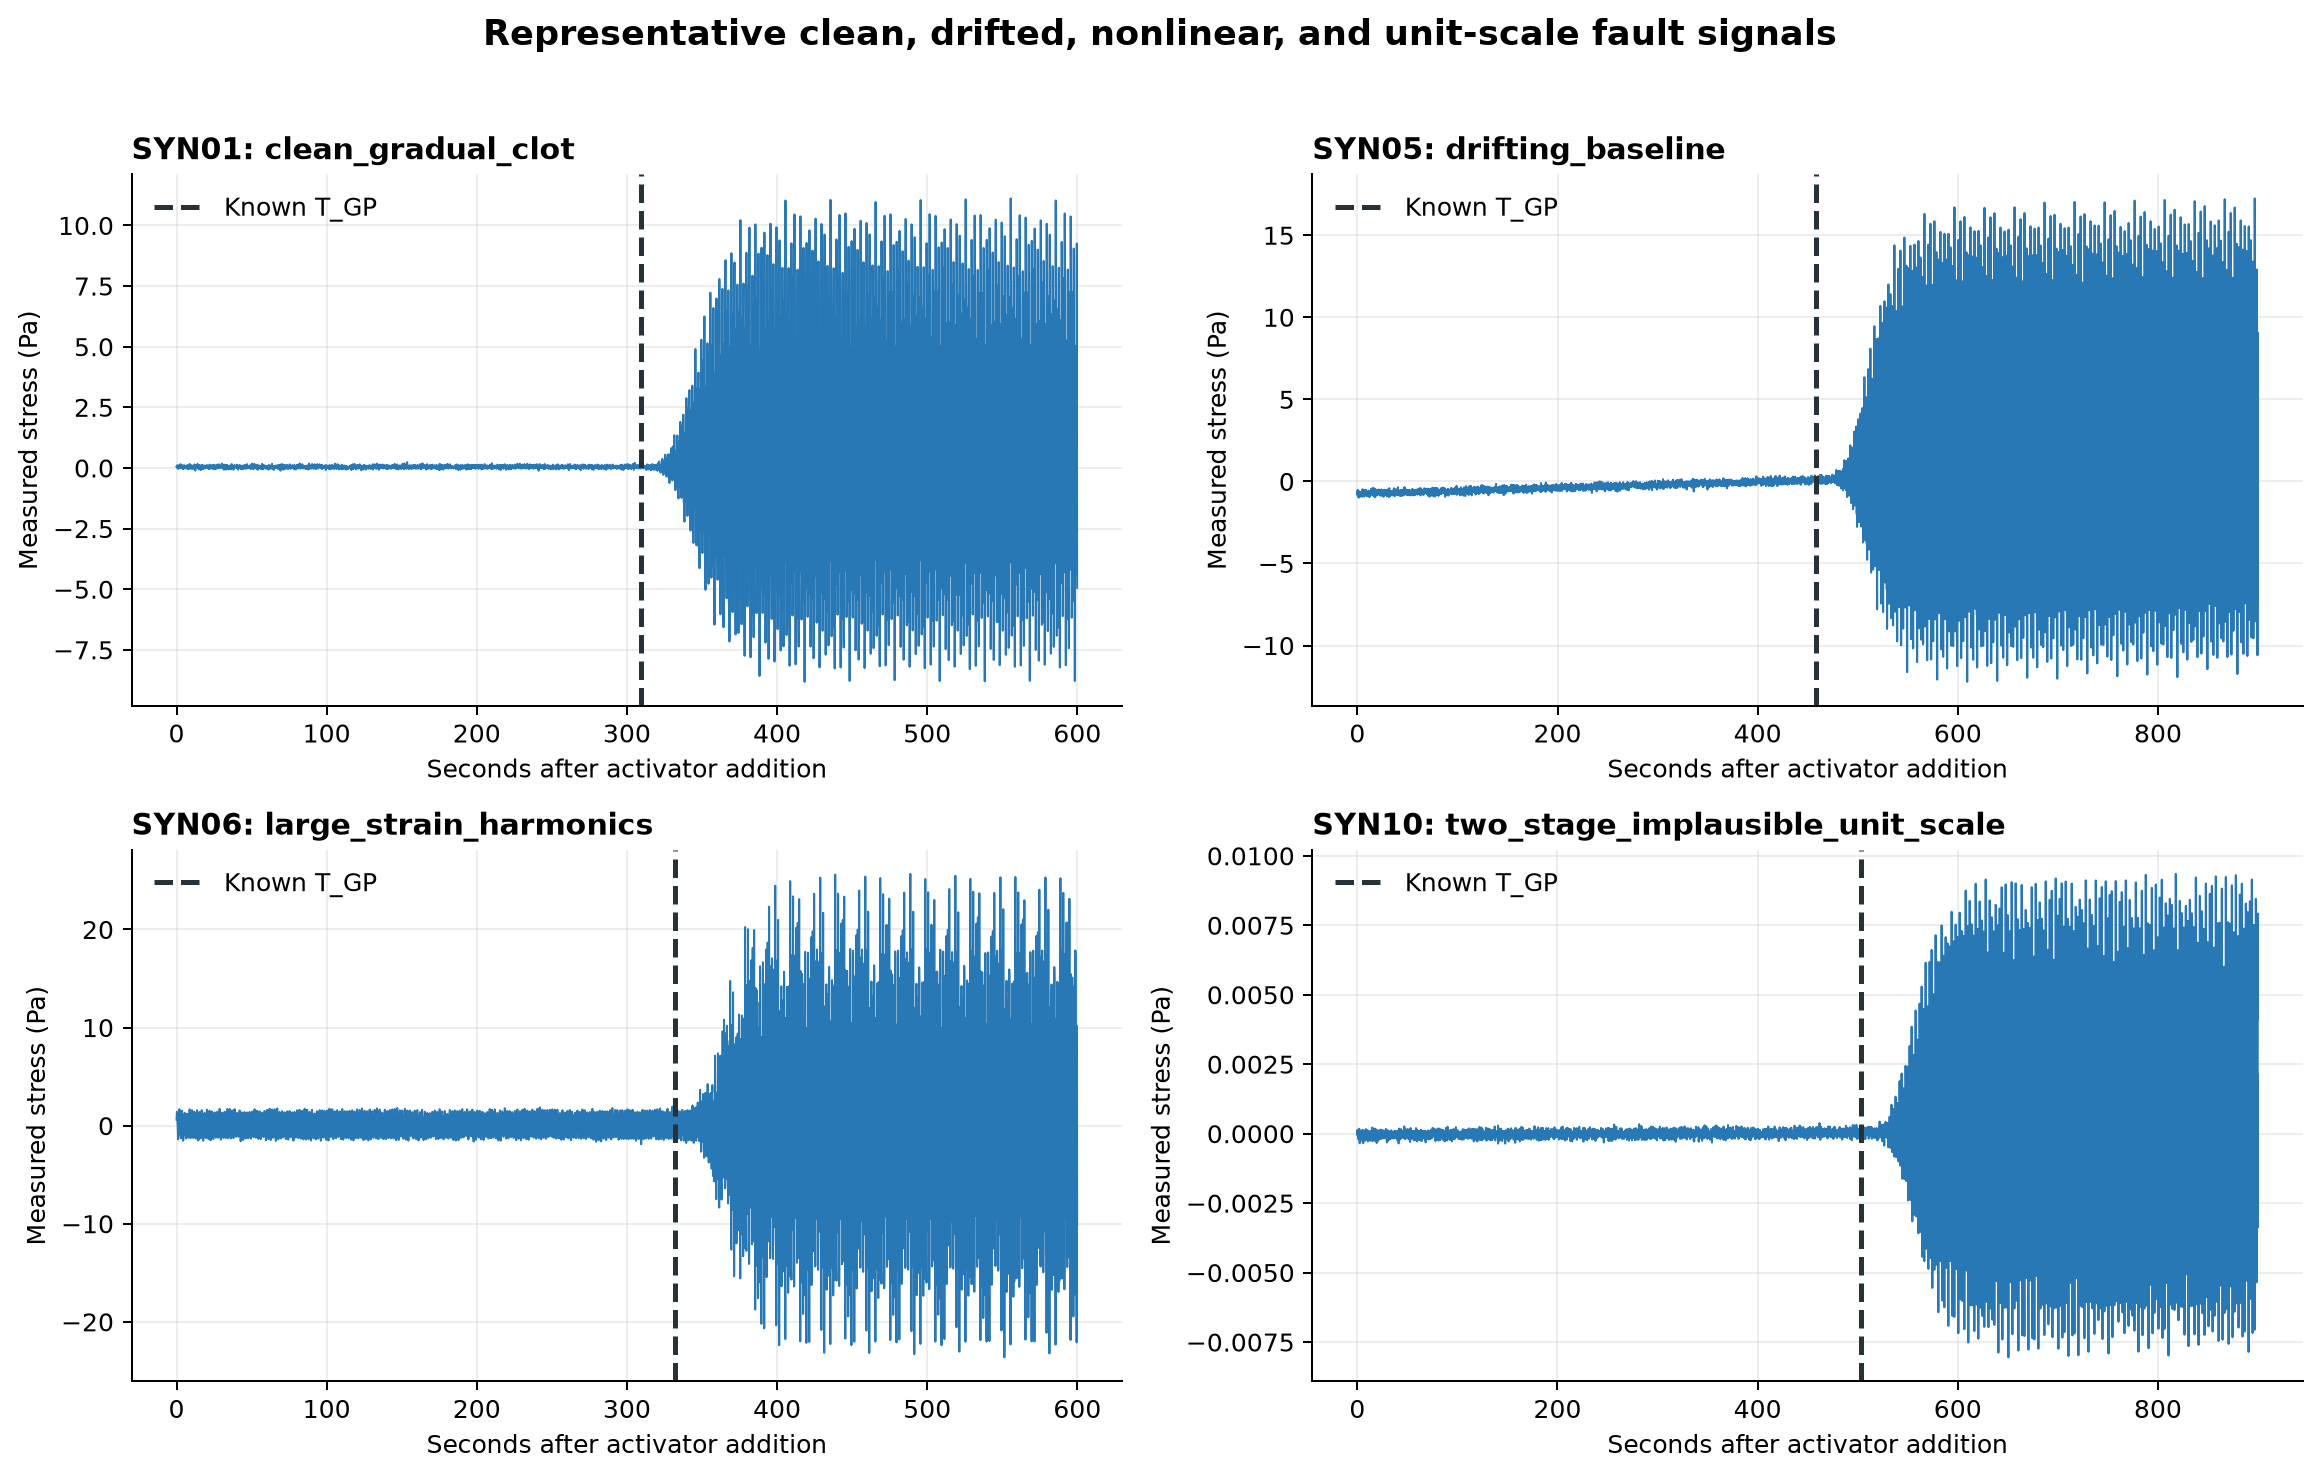

In [ ]:
# Plotting representative observed stress signals and known clot times
selected_datasets = ["SYN01","SYN05","SYN06","SYN10"]
figure, axes = plt.subplots(2, 2, figsize=(13, 8))
for axis, dataset_id in zip(axes.ravel(), selected_datasets):
    record = next(row for row in manifest_records if row["dataset_id"] == dataset_id)
    observations = pd.read_csv(data_directory / record["csv_file"])
    run_id = f"{dataset_id}_R01"
    selected = observations[observations["run_id"].eq(run_id)]
    truth_time = float(truth_lookup.loc[run_id, "ground_truth_gel_time_s"])
    skip = max(1, int(round(float(selected["nominal_sampling_rate_hz"].iloc[0]) / 8.0)))
    axis.plot(selected["time_s"].to_numpy()[::skip], selected["stress_measured_pa"].to_numpy()[::skip], color="#2878B5", lw=0.8)
    axis.axvline(truth_time, color=plot_colours["Truth"], ls="--", lw=2, label="Known T_GP")
    axis.set_title(f'{dataset_id}: {record["scenario_name"]}', loc="left")
    axis.set_xlabel("Seconds after activator addition")
    axis.set_ylabel("Measured stress (Pa)")
    axis.legend(frameon=False)
figure.suptitle("Representative clean, drifted, nonlinear, and unit-scale fault signals", y=1.02, fontsize=14, fontweight="bold")
figure.tight_layout()
figure.savefig(figure_directory / "01_observed_signals.png", dpi=180, bbox_inches="tight")
plt.show()

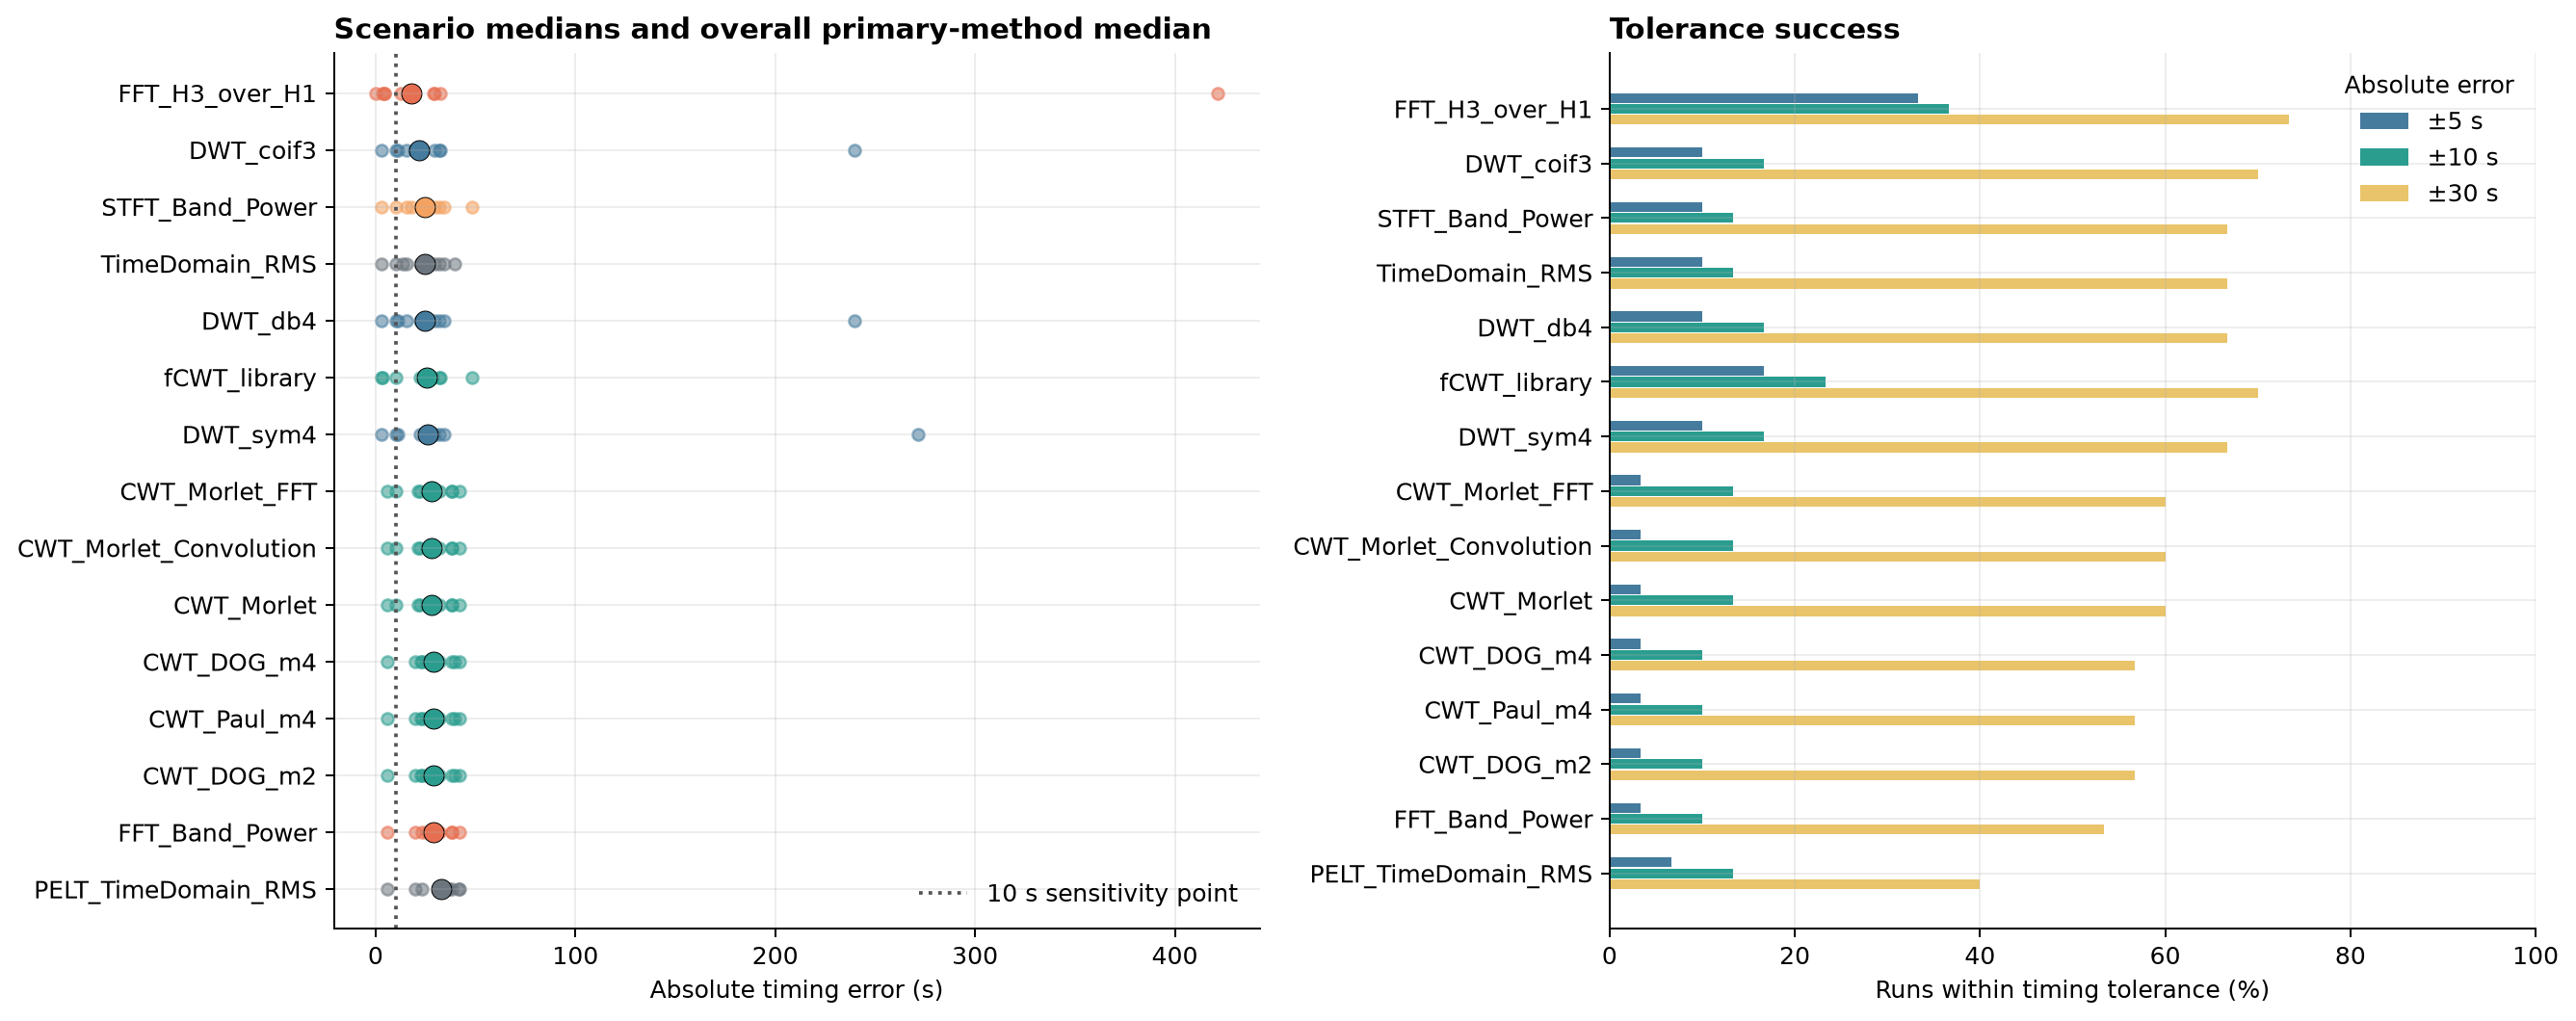

In [ ]:
# Plotting method timing error and tolerance success
ordered_summary = primary_summary.sort_values("median_absolute_error_s")
figure, axes = plt.subplots(1, 2, figsize=(15, max(6, 0.38 * len(ordered_summary))))
for row_index, row in enumerate(ordered_summary.itertuples(index=False)):
    family_colour = plot_colours.get(row.method_family, plot_colours["Baseline"])
    scenario_values = scenario_summary.loc[
        scenario_summary["method"].eq(row.method),
        "scenario_median_absolute_error_s",
    ].dropna().to_numpy()
    axes[0].scatter(scenario_values, np.full(len(scenario_values), row_index), s=24, alpha=0.55, color=family_colour)
    axes[0].scatter(row.median_absolute_error_s, row_index, s=70, color=family_colour, edgecolor="black", linewidth=0.4)
axes[0].set_yticks(np.arange(len(ordered_summary)))
axes[0].set_yticklabels(ordered_summary["method"])
axes[0].invert_yaxis()
axes[0].set_xlabel("Absolute timing error (s)")
axes[0].set_title("Scenario medians and overall primary-method median", loc="left")
axes[0].axvline(10, color="#555555", ls=":", label="10 s sensitivity point")
axes[0].legend(frameon=False)

y_positions = np.arange(len(ordered_summary))
for offset, column, label, colour in [
    (-0.20,"within_5s","±5 s","#457B9D"),
    (0.00,"within_10s","±10 s","#2A9D8F"),
    (0.20,"within_30s","±30 s","#E9C46A"),
]:
    axes[1].barh(y_positions + offset, ordered_summary[column] * 100, height=0.18, label=label, color=colour)
axes[1].set_yticks(y_positions)
axes[1].set_yticklabels(ordered_summary["method"])
axes[1].invert_yaxis()
axes[1].set_xlim(0,100)
axes[1].set_xlabel("Runs within timing tolerance (%)")
axes[1].set_title("Tolerance success", loc="left")
axes[1].legend(title="Absolute error", frameon=False)
figure.tight_layout()
figure.savefig(figure_directory / "02_timing_and_tolerance.png", dpi=180, bbox_inches="tight")
plt.show()

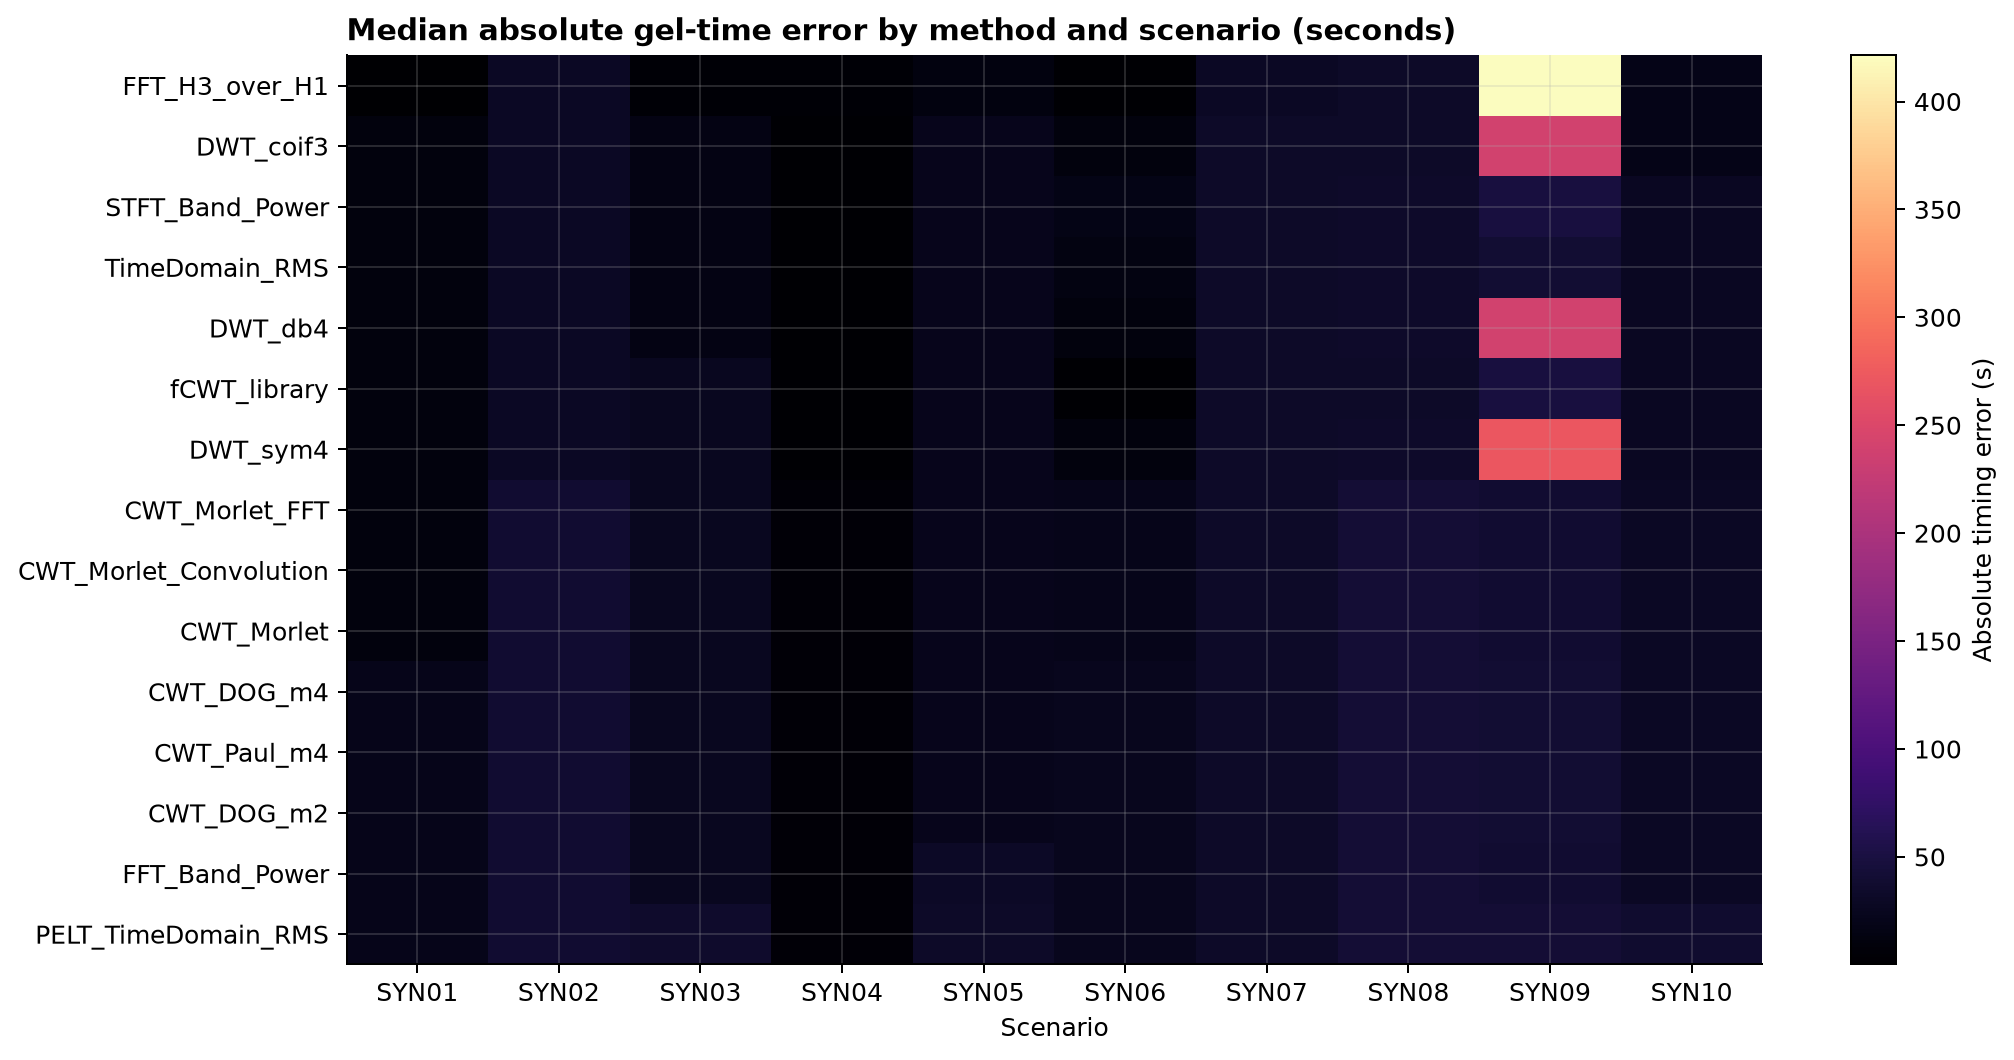

In [ ]:
# Plotting per-scenario error to reveal failure modes hidden by the overall median
heatmap = scenario_summary.pivot(index="method", columns="dataset_id", values="scenario_median_absolute_error_s")
heatmap = heatmap.reindex(ordered_summary["method"])
figure, axis = plt.subplots(figsize=(12, max(6, 0.38 * len(heatmap))))
image = axis.imshow(heatmap.to_numpy(), aspect="auto", cmap="magma", interpolation="nearest")
axis.set_xticks(np.arange(len(heatmap.columns)))
axis.set_xticklabels(heatmap.columns)
axis.set_yticks(np.arange(len(heatmap.index)))
axis.set_yticklabels(heatmap.index)
axis.set_xlabel("Scenario")
axis.set_title("Median absolute gel-time error by method and scenario (seconds)", loc="left")
figure.colorbar(image, ax=axis, label="Absolute timing error (s)")
figure.tight_layout()
figure.savefig(figure_directory / "03_error_heatmap.png", dpi=180, bbox_inches="tight")
plt.show()

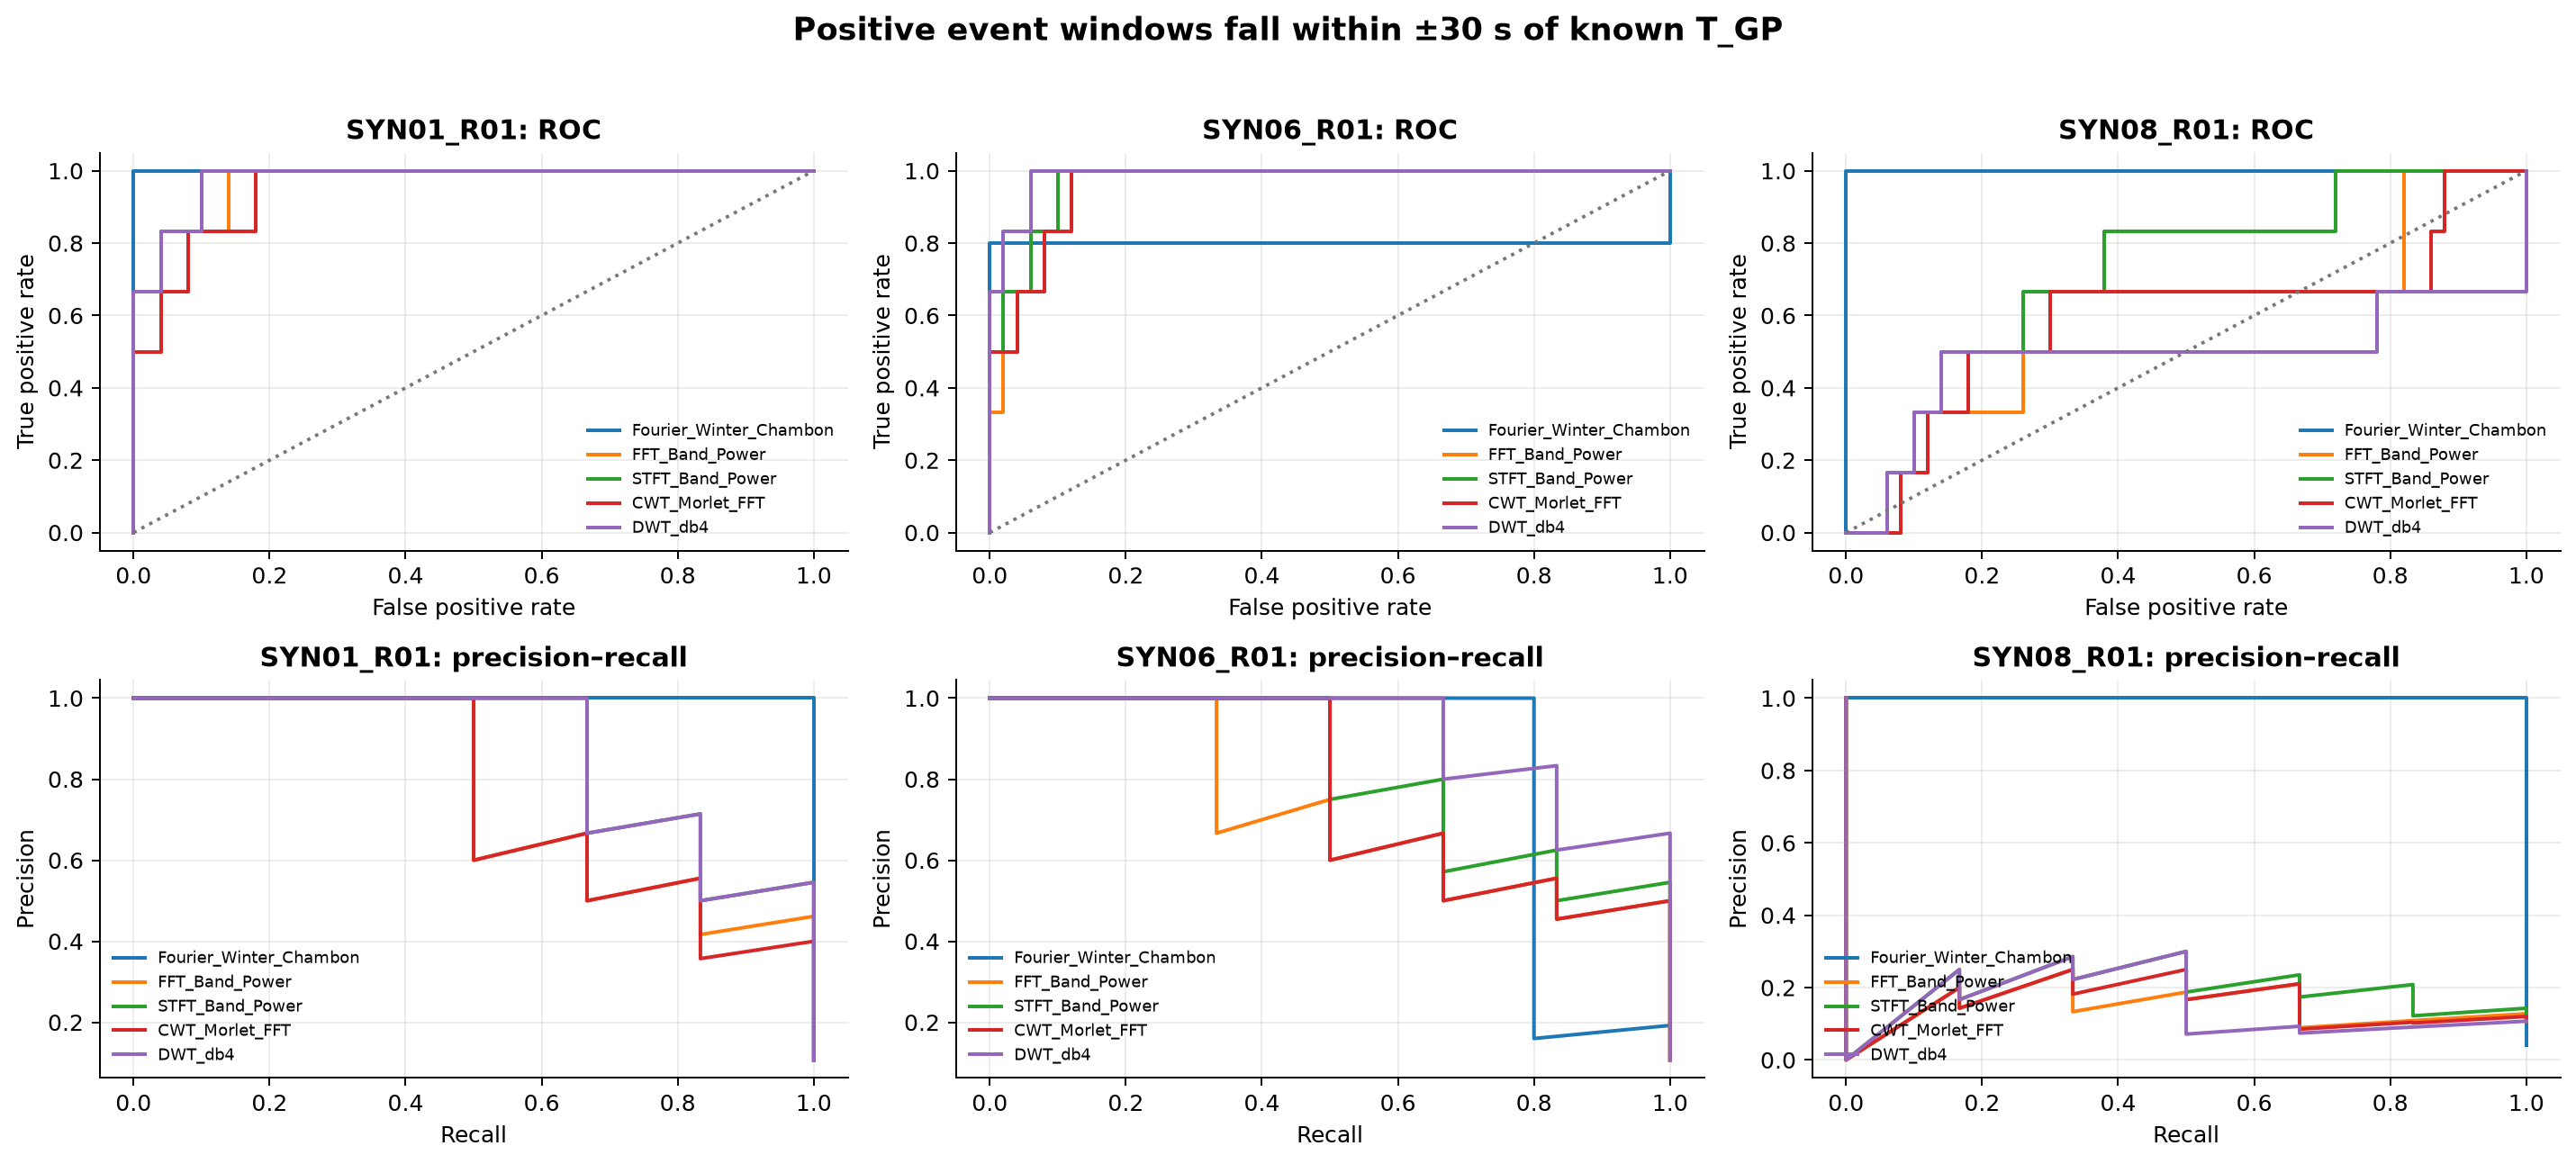

In [ ]:
# Plotting event-window ROC and precision-recall curves on three distinct signals
selected_run_ids = ["SYN01_R01","SYN06_R01","SYN08_R01"]
selected_methods = [
    name for name in ["FFT_H3_over_H1","FFT_Band_Power","STFT_Band_Power","CWT_Morlet_FFT","DWT_db4"]
    if name in family_by_method
]
figure, axes = plt.subplots(2, 3, figsize=(16, 7))
for column, run_id in enumerate(selected_run_ids):
    this_run = window_scores[window_scores["run_id"].eq(run_id)]
    for method in selected_methods:
        values = this_run[
            this_run["method"].eq(method) & this_run["window_valid"] & this_run["event_score"].notna()
        ]
        labels = values["event_window_positive"].to_numpy(dtype=bool)
        scores = values["event_score"].to_numpy(dtype=float)
        if len(np.unique(labels)) < 2:
            continue
        false_positive, true_positive, _ = roc_curve(labels, scores)
        precision, recall, _ = precision_recall_curve(labels, scores)
        axes[0,column].plot(false_positive, true_positive, lw=1.6, label=method)
        axes[1,column].plot(recall, precision, lw=1.6, label=method)
    axes[0,column].plot([0,1],[0,1], color="#777777", ls=":")
    axes[0,column].set_title(f"{run_id}: ROC")
    axes[0,column].set_xlabel("False positive rate")
    axes[0,column].set_ylabel("True positive rate")
    axes[1,column].set_title(f"{run_id}: precision–recall")
    axes[1,column].set_xlabel("Recall")
    axes[1,column].set_ylabel("Precision")
    axes[0,column].legend(fontsize=7, frameon=False, loc="lower right")
    axes[1,column].legend(fontsize=7, frameon=False, loc="lower left")
figure.suptitle("Positive event windows fall within ±30 s of known T_GP", y=1.02, fontsize=14, fontweight="bold")
figure.tight_layout()
figure.savefig(figure_directory / "04_event_window_curves.png", dpi=180, bbox_inches="tight")
plt.show()

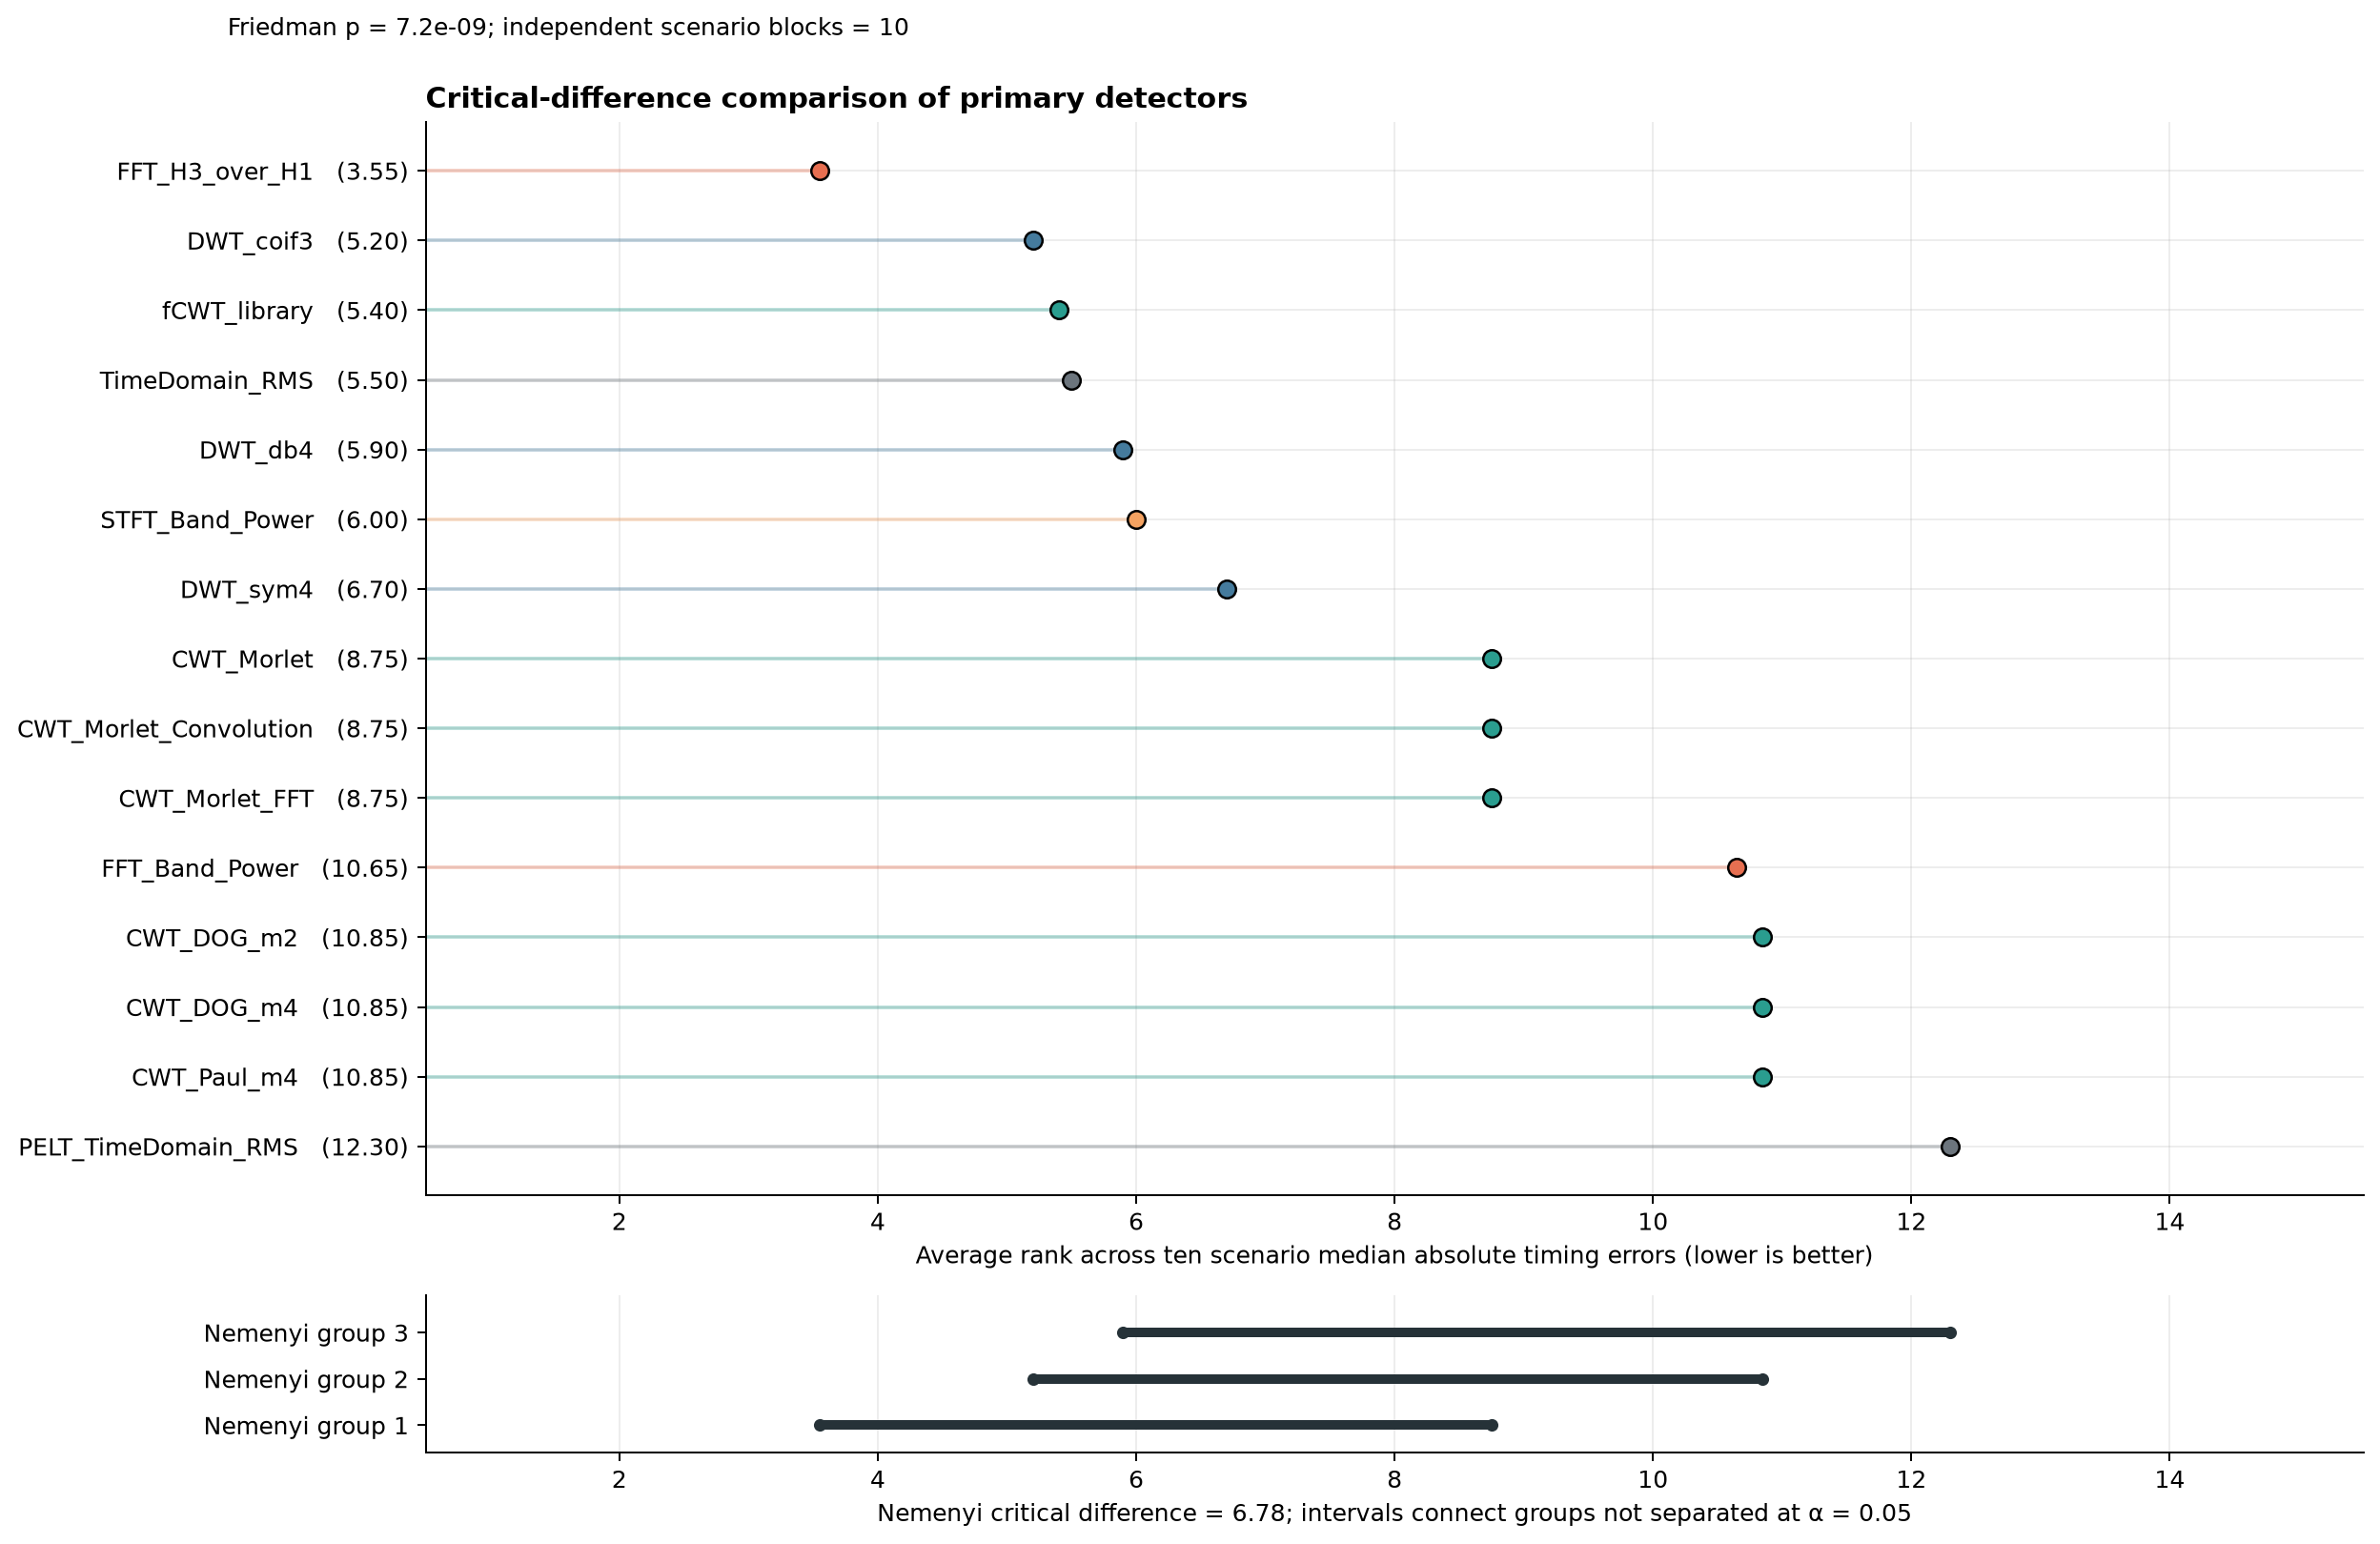

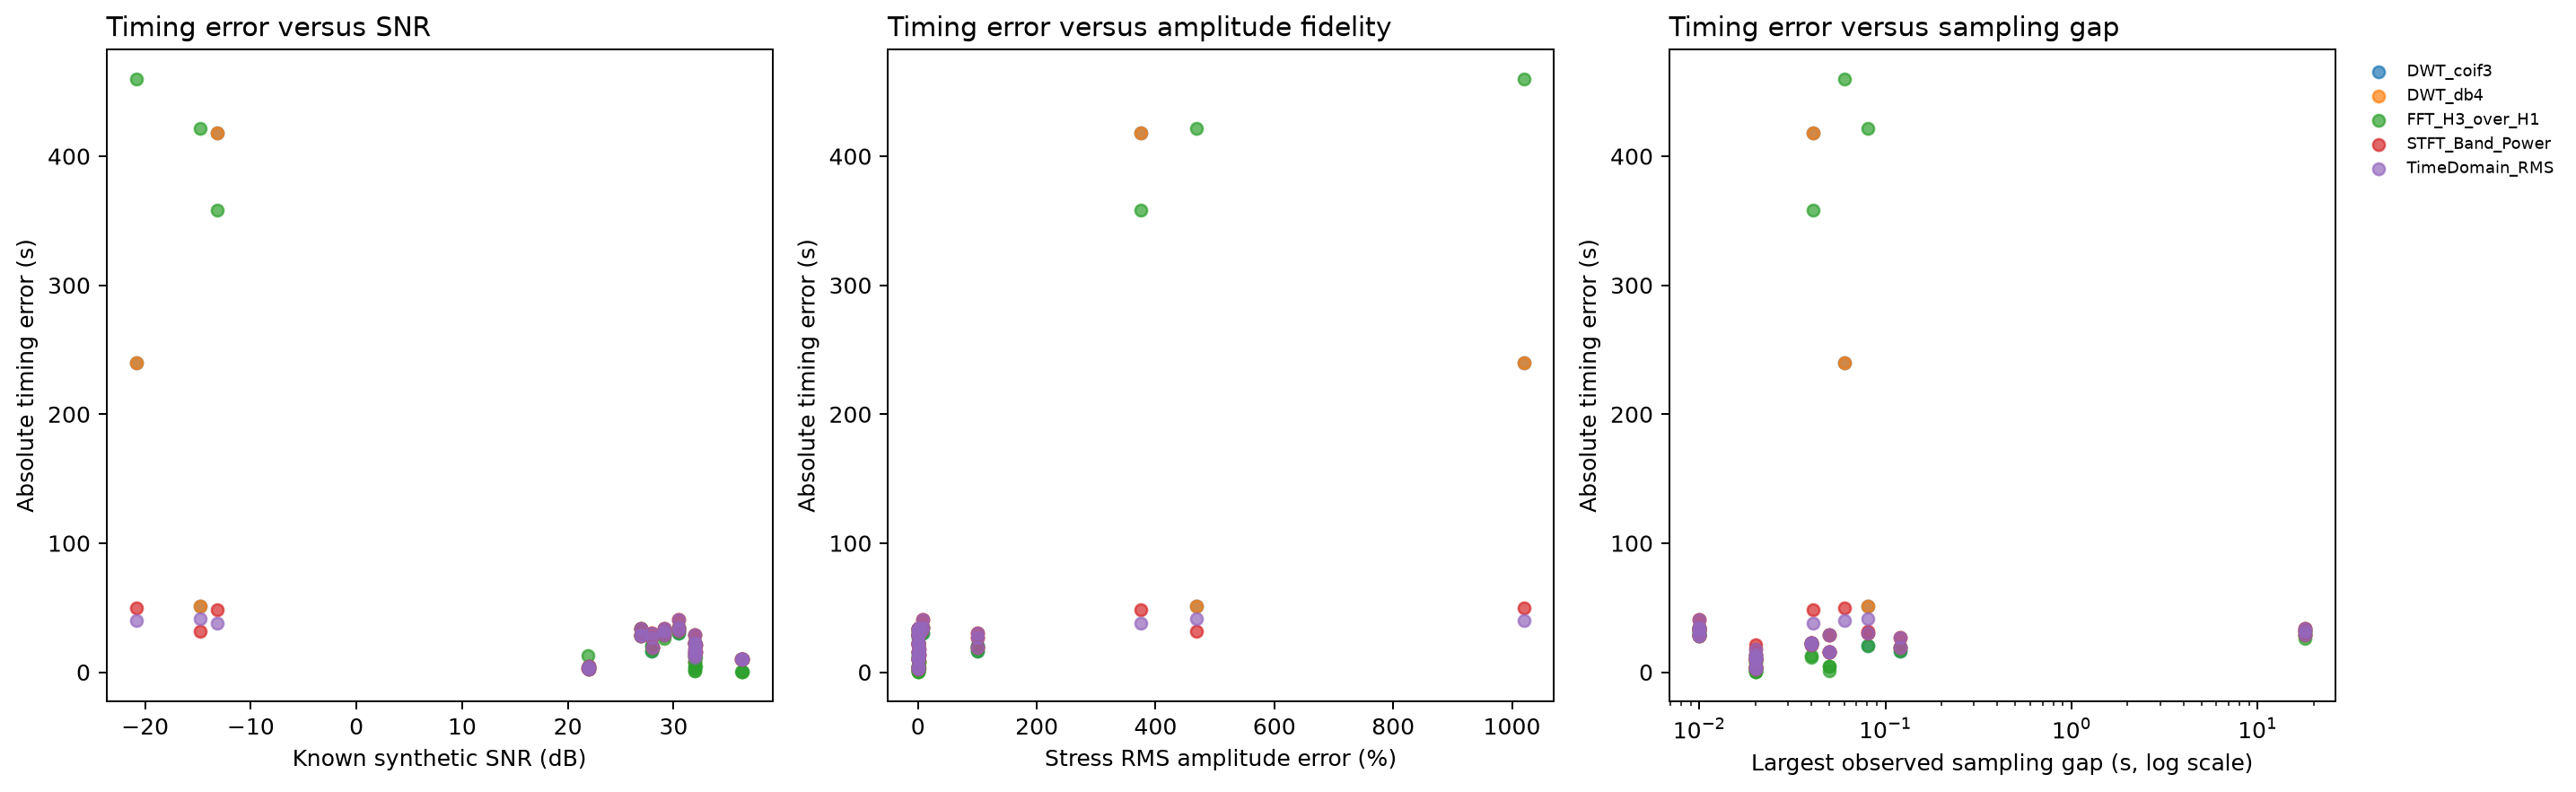

In [ ]:
# Creating a readable critical-difference rank view for primary methods
rank_matrix = error_matrix[complete_methods].rank(axis=1, method="average", ascending=True)
average_ranks = rank_matrix.mean(axis=0).sort_values()
critical_difference = np.nan
try:
    from scipy.stats import studentized_range
    q_critical = studentized_range.ppf(0.95, len(average_ranks), np.inf) / np.sqrt(2.0)
    critical_difference = float(q_critical * np.sqrt(
        len(average_ranks) * (len(average_ranks)+1) / (6.0 * len(rank_matrix))
    ))
except Exception:
    pass

sorted_methods = average_ranks.index.to_list()
method_positions = np.arange(len(sorted_methods))
figure, (rank_axis, group_axis) = plt.subplots(
    2, 1, figsize=(14, 9), gridspec_kw={"height_ratios":[len(sorted_methods), 2.2]}
)
for method_position, method_name in enumerate(sorted_methods):
    rank_value = float(average_ranks[method_name])
    family = family_by_method.get(method_name, "Baseline")
    family_colour = plot_colours.get(family, plot_colours["Baseline"])
    rank_axis.hlines(method_position, 0.5, rank_value, color=family_colour, alpha=0.35, linewidth=1.5)
    rank_axis.scatter(rank_value, method_position, color=family_colour, edgecolor="black", s=55, zorder=3)

rank_axis.set_yticks(method_positions)
rank_axis.set_yticklabels([f"{method}   ({average_ranks[method]:.2f})" for method in sorted_methods])
rank_axis.invert_yaxis()
rank_axis.set_xlim(0.5, len(average_ranks)+0.5)
rank_axis.set_xlabel("Average rank across ten scenario median absolute timing errors (lower is better)")
rank_axis.set_title("Critical-difference comparison of primary detectors", loc="left")

nonsignificant_groups = []
for group_start in range(len(sorted_methods)):
    for group_end in range(group_start + 1, len(sorted_methods)):
        rank_span = average_ranks.iloc[group_end] - average_ranks.iloc[group_start]
        if np.isfinite(critical_difference) and rank_span <= critical_difference:
            nonsignificant_groups.append((group_start, group_end))
maximal_groups = [
    group for group in nonsignificant_groups
    if not any(group[0] >= other[0] and group[1] <= other[1] and group != other for other in nonsignificant_groups)
]
for group_position, (group_start, group_end) in enumerate(maximal_groups):
    left_rank = float(average_ranks.iloc[group_start])
    right_rank = float(average_ranks.iloc[group_end])
    group_axis.plot([left_rank, right_rank], [group_position, group_position], color="#263238", lw=4, solid_capstyle="round")
    group_axis.scatter([left_rank, right_rank], [group_position, group_position], color="#263238", s=18)

group_axis.set_xlim(0.5, len(average_ranks)+0.5)
group_axis.set_ylim(-0.6, max(len(maximal_groups),1)-0.2)
group_axis.set_yticks(np.arange(len(maximal_groups)))
group_axis.set_yticklabels([f"Nemenyi group {group_number}" for group_number in range(1,len(maximal_groups)+1)])
group_axis.set_xlabel(f"Nemenyi critical difference = {critical_difference:.2f}; intervals connect groups not separated at α = 0.05")
group_axis.grid(axis="y", visible=False)
figure.suptitle(f"Friedman p = {friedman_p:.3g}; independent scenario blocks = {len(rank_matrix)}", x=0.10, y=0.995, ha="left", fontsize=10)
figure.tight_layout()
figure.savefig(figure_directory / "05_critical_difference.png", dpi=180, bbox_inches="tight")
plt.show()

quality_join = available.merge(
    quality_table[["run_id","dataset_id","known_snr_db","sampling_interval_cv","missing_fraction","clipped_fraction","stress_rms_amplitude_error_percent","maximum_observed_gap_s","unit_scale_fault"]],
    on=["run_id","dataset_id"], how="left",
)
top_methods = primary_summary.head(5)["method"].tolist()
quality_join = quality_join[quality_join["method"].isin(top_methods)].copy()
figure, axes = plt.subplots(1,3,figsize=(16,5))
for method, method_rows in quality_join.groupby("method"):
    axes[0].scatter(method_rows["known_snr_db"],method_rows["absolute_timing_error_s"],s=28,alpha=0.7,label=method)
    axes[1].scatter(method_rows["stress_rms_amplitude_error_percent"],method_rows["absolute_timing_error_s"],s=28,alpha=0.7,label=method)
    axes[2].scatter(method_rows["maximum_observed_gap_s"],method_rows["absolute_timing_error_s"],s=28,alpha=0.7,label=method)
axes[0].set_xlabel("Known synthetic SNR (dB)")
axes[0].set_ylabel("Absolute timing error (s)")
axes[0].set_title("Timing error versus SNR",loc="left")
axes[1].set_xlabel("Stress RMS amplitude error (%)")
axes[1].set_ylabel("Absolute timing error (s)")
axes[1].set_title("Timing error versus amplitude fidelity",loc="left")
axes[2].set_xscale("log")
axes[2].set_xlabel("Largest observed sampling gap (s, log scale)")
axes[2].set_ylabel("Absolute timing error (s)")
axes[2].set_title("Timing error versus sampling gap",loc="left")
axes[2].legend(fontsize=7,frameon=False,bbox_to_anchor=(1.02,1),loc="upper left")
figure.tight_layout()
figure.savefig(figure_directory / "06_quality_robustness.png",dpi=180,bbox_inches="tight")
plt.show()


## Validation, exported parameter dictionary, and limitations

The validation table checks the ten scenario files, row counts, separate truth labels, and run count. The feature dictionary distinguishes event detection metrics from signal-quality descriptors. The SNR is computed from known clean synthetic stress and injected noise; it is a simulator audit value, not an observable clinical measurement.

The 40-second outer window limits temporal resolution. A ±5-second success result should be interpreted in light of that window support. The event-window ROC/PR task and the gel-time regression task remain separate. Ten scenario families provide only ten independent blocks for Friedman ranks; statistical conclusions are exploratory. The criterion-aligned positive control is deliberately excluded from the primary method ranking.

Chirp-specific mutation-number and time–bandwidth thresholds are outside this multisine design. ADF stationarity is also not used as a hard gate because the intended clot signal is time-varying; the notebook instead records whether each shared window has adequate sampling support.


In [ ]:
# Saving validation checks, transform settings, feature definitions, and reporting table
validation = pd.DataFrame([
    ["Ten scenario files",len(manifest_table)==10,len(manifest_table)],
    ["Every scenario has at least 10,000 rows",bool((manifest_table["retained_rows"]>=10000).all()),int(manifest_table["retained_rows"].min())],
    ["Every replicate has at least 10,000 rows",bool((manifest_table["minimum_rows_per_replicate"]>=10000).all()),int(manifest_table["minimum_rows_per_replicate"].min())],
    ["Thirty separate known gel-time labels",truth_table["run_id"].nunique()==30,truth_table["run_id"].nunique()],
    ["Unit-scale fault is tagged",bool(quality_table["unit_scale_fault"].any()),int(quality_table["unit_scale_fault"].sum())],
    ["Timing-window calculations retain gaps",bool(quality_table["maximum_observed_gap_s"].notna().all()),float(quality_table["maximum_observed_gap_s"].max())],
    ["Ground truth stored outside observed CSVs",(output_directory/"ground_truth_labels.csv").exists(),"separate label file"],
],columns=["validation_check","passed","observed"])
validation.to_csv(output_directory/"validation_checks.csv",index=False)

settings = pd.DataFrame([
    ["Shared outer windows","40 s; 10 s hop","All methods share window centers and validity mask."],
    ["Gel-time boundary cases","Early and late clot points","SYN04 has limited pre-gel support; SYN09 has limited post-gel support."],
    ["Missing transition","18 s gap centered at T_GP","Affected windows are invalidated for every method."],
    ["Stress scale fault","0.001 × nominal stress, still tagged Pa","Intentional unit-consistency fault; amplitude-fidelity error is exported."],
    ["Irregular-time handling","Linear interpolation to nominal sampling grid","No extrapolation beyond observed support; long gaps invalidate shared windows."],
    ["Main preprocessing","Window-wise mean removal","Linear drift is retained as a robustness challenge."],
    ["FFT/STFT","Hann taper; 0.15 Hz to min(8 Hz, 0.40 × sample rate)","STFT inner segment 4 s with 75% overlap."],
    ["CWT families","Morlet, Paul m=4, DOG m=2 and m=4","Torrence and Compo (1998), Eqs. 1–4 and Table 1, pp. 62–64; common six-frequency grid; central half reduces edge effects."],
    ["Fast CWT","PyWavelets Morlet method=fft and method=conv","Optional fcwt package is separate and its load status is reported."],
    ["DWT bases","db4, sym4, coif3; up to level 5","Mallat (1989), multiresolution signal decomposition; symmetric boundary extension; detail energy per sample."],
    ["PELT","L2 cost; penalty 2 × variance × log(window count)","Explicit benchmark setting, not a literature acceptance threshold."],
    ["Statistical comparisons","Friedman, Holm-adjusted Wilcoxon, Nemenyi CD","Demšar (2006), §§3.1.3, 3.2.2, 3.2.4; ten independent scenario blocks."],
    ["Statistical comparisons","Friedman, Holm-adjusted Wilcoxon, Nemenyi CD","Demšar (2006), §§3.1.3, 3.2.2, 3.2.4; ten independent scenario blocks."],
    ["Timing tolerances","±5, ±10, ±30 s","Sensitivity points, not confirmed clinical thresholds."],
],columns=["setting","configuration","handling"])
settings.to_csv(output_directory/"transform_parameter_table.csv",index=False)

dictionary = pd.DataFrame([
    ["TimeDomain_RMS","Log RMS stress per shared window","Overall signal magnitude."],
    ["FFT_Band_Power","Log Hann-windowed Fourier power in rheology band","Global Fourier energy-change feature."],
    ["FFT_H3_over_H1","Log third-to-first harmonic ratio","Nonlinear distortion descriptor, not gel-point definition."],
    ["STFT_Band_Power","Log short-time Fourier power in rheology band","Localized Fourier energy-change feature."],
    ["CWT family features","Log wavelet coefficient power across selected scales","Localized time-scale energy-change features."],
    ["DWT family features","Log summed detail coefficient energy per sample","Multiresolution detail-energy features."],
    ["Fourier_Winter_Chambon","Negative operational mismatch of fitted slopes, phase spread, and power-law fits","Criterion-aligned positive control; excluded from primary ranking because the synthetic truth uses this condition."],
    ["Fourier_Gprime_Gdoubleprime_Crossover","Negative absolute log ratio of G' and G'' at lowest shared frequency","Secondary rheological comparator; not the primary truth definition."],
    ["ROC AUC and average precision","Window-score discrimination for labels within ±30 s of T_GP","Localization metrics, not gel-time error."],
    ["Stress RMS amplitude error","Absolute percent difference between measured and clean RMS","Synthetic signal fidelity; sensitive to gain, noise, drift, and clipping."],
    ["Runtime","Median feature extraction and detector time per run, in ms","Environment-dependent timing; compare on the same machine and software stack."],
    ["Spearman rho","Rank association between predicted and true gel time","Ordering only; not agreement or calibration."],
],columns=["feature_or_metric","definition","interpretation"])
dictionary.to_csv(output_directory/"feature_dictionary.csv",index=False)

report_table = summary.sort_values("median_absolute_error_s")
report_table.to_csv(output_directory/"reporting_table.csv",index=False)
display(validation)
print(f"Rows in ten scenario files: {manifest_table['retained_rows'].sum():,}")
print(f"Tables and figures saved under {output_directory}")
print(f"fCWT library status: {fcwt_status}")
display(report_table.round(3))

validation_check,passed,observed
Ten scenario files,True,10.000
"Every scenario has at least 10,000 rows",True,54000.000
"Every replicate has at least 10,000 rows",True,18000.000
Thirty separate known gel-time labels,True,30.000
Unit-scale fault is tagged,True,3.000
Timing-window calculations retain gaps,True,18.032
Ground truth stored outside observed CSVs,True,separate label file


## Reproducibility notes

- A fixed seed reproduces the synthetic measurements; three noise realizations are generated per scenario.
- Replicates are nested within ten scenario families. They are summarized before the paired rank tests.
- The gel point is the exact synthetic Winter–Chambon midpoint. A \(G'=G''\) time is labeled separately.
- Values and fault levels are simulation settings, not validated Haemograph operating limits.
- Mutation-number and time–bandwidth cutoffs from the draft benchmark list are not used: those criteria were developed for chirp protocols and have not been validated for this multisine design.
- The optional fCWT binary may fail to load when its OpenMP dependency is missing. The notebook records that status and continues with the PyWavelets FFT-based CWT.
- The primary method ranking is absolute timing error by scenario. ROC AUC, average precision, Spearman rho, and rank tests provide supporting views; none alone establishes clinical suitability.